## **DATA ANALYSIS WORKFLOW:**

1. Importing Libraries

2. Importing dataset

3. Understand the data (EDA- Exploratory Data Analysis)

4. Data Preprocessing:

Missing Values

Null Values

Invalid values

Encoding(If needed)

5. Scaling

6. Visualization/analysis

 - Univariate

 - Bi-Variate

 - Multi-variate

7. Insights/Conclusion from visualizations


## Description

This dataset contains information about banking marketing campaigns, including customer demographics, financial details, contact information, and campaign outcomes. Below is a description of each column:

| Column Name    | Description                                                               |
| :------------- | :------------------------------------------------------------------------ |
| `customerid`   | Unique identifier for each customer.                                      |
| `age`          | Age of the customer.                                                      |
| `salary`       | Customer's annual salary.                                                 |
| `balance`      | Customer's average yearly balance.                                        |
| `marital`      | Marital status of the customer (e.g., married, single, divorced).         |
| `jobedu`       | Customer's job type and education level (combined or concatenated).       |
| `targeted`     | Indicates whether the particular customer was targeted before.            |
| `default`      | Has credit in default? (Yes/No).                                          |
| `housing`      | Has housing loan? (Yes/No).                                               |
| `loan`         | Has personal loan? (Yes/No).                                              |
| `contact`      | Contact communication type (e.g., cellular, telephone).                   |
| `day`          | Day of the month when the last contact was performed.                     |
| `month`        | Month of the year when the last contact was performed.                    |
| `duration`     | Last contact duration in seconds.                                         |
| `campaign`     | Number of contacts performed during this campaign for this customer.      |
| `pdays`        | Number of days that passed after the customer was last contacted from a previous campaign. -1 means customer was not previously contacted. |
| `previous`     | Number of contacts performed before this campaign and for this customer.  |
| `poutcome`     | Outcome of the previous marketing campaign.                               |
| `response`     | Has the client subscribed to a term deposit? (Yes/No). This is the target variable. |


# Importing Libraries

In [1]:
import pandas as pd                 # data manipulation
import numpy as np                  # numerical methods
import matplotlib.pyplot as plt     # visualizations
import seaborn as sns               # advance visualizations
%matplotlib inline

import warnings
warnings.filterwarnings('ignore')

# Importing Dataset


* excel file: read_excel("dataset name.xlsx")
* json file: read_json("dataset name.json")

In [2]:
df = pd.read_csv("/content/drive/MyDrive/AICW/EDA/bank_customer data.csv")
df.head()

,banking marketing,Unnamed: 1,Unnamed: 2,Unnamed: 3,Unnamed: 4,Unnamed: 5,Unnamed: 6,Unnamed: 7,Unnamed: 8,Unnamed: 9,Unnamed: 10,Unnamed: 11,Unnamed: 12,Unnamed: 13,Unnamed: 14,Unnamed: 15,Unnamed: 16,Unnamed: 17,Unnamed: 18
0,customer id and age.,NaN,Customer salary and balance.,NaN,Customer marital status and job with education...,NaN,particular customer before targeted or not,NaN,Loan types: loans or housing loans,NaN,Contact type,NaN,month of contact,duration of call,NaN,NaN,NaN,outcome of previous contact,response of customer after call happned
1,customerid,age,salary,balance,marital,jobedu,targeted,default,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,response
2,1,58,100000,2143,married,"management,tertiary",yes,no,yes,no,unknown,5,"may, 2017",261 sec,1,-1,0,unknown,no
3,2,44,60000,29,single,"technician,secondary",yes,no,yes,no,unknown,5,"may, 2017",151 sec,1,-1,0,unknown,no
4,3,33,120000,2,married,"entrepreneur,secondary",yes,no,yes,yes,unknown,5,"may, 2017",76 sec,1,-1,0,unknown,no


In [3]:
df = pd.read_csv("/content/drive/MyDrive/AICW/EDA/bank_customer data.csv",skiprows = 2)
df.head()

,customerid,age,salary,balance,marital,jobedu,targeted,default,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,response
0,1,58.0,100000,2143,married,"management,tertiary",yes,no,yes,no,unknown,5,"may, 2017",261 sec,1,-1,0,unknown,no
1,2,44.0,60000,29,single,"technician,secondary",yes,no,yes,no,unknown,5,"may, 2017",151 sec,1,-1,0,unknown,no
2,3,33.0,120000,2,married,"entrepreneur,secondary",yes,no,yes,yes,unknown,5,"may, 2017",76 sec,1,-1,0,unknown,no
3,4,47.0,20000,1506,married,"blue-collar,unknown",no,no,yes,no,unknown,5,"may, 2017",92 sec,1,-1,0,unknown,no
4,5,33.0,0,1,single,"unknown,unknown",no,no,no,no,unknown,5,"may, 2017",198 sec,1,-1,0,unknown,no


In [4]:
df.shape

(45211, 19)

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 19 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   customerid  45211 non-null  int64  
 1   age         45191 non-null  float64
 2   salary      45211 non-null  int64  
 3   balance     45211 non-null  int64  
 4   marital     45211 non-null  object 
 5   jobedu      45211 non-null  object 
 6   targeted    45211 non-null  object 
 7   default     45211 non-null  object 
 8   housing     45211 non-null  object 
 9   loan        45211 non-null  object 
 10  contact     45211 non-null  object 
 11  day         45211 non-null  int64  
 12  month       45161 non-null  object 
 13  duration    45211 non-null  object 
 14  campaign    45211 non-null  int64  
 15  pdays       45211 non-null  int64  
 16  previous    45211 non-null  int64  
 17  poutcome    45211 non-null  object 
 18  response    45181 non-null  object 
dtypes: float64(1), int64(7), 

In [6]:
df.describe()

,customerid,age,salary,balance,day,campaign,pdays,previous
count,45211.000000,45191.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000
mean,22606.000000,40.935651,57006.171065,1362.272058,15.806419,2.763841,40.197828,0.580323
std,13051.435847,10.619198,32085.718415,3044.765829,8.322476,3.098021,100.128746,2.303441
min,1.000000,18.000000,0.000000,-8019.000000,1.000000,1.000000,-1.000000,0.000000
25%,11303.500000,33.000000,20000.000000,72.000000,8.000000,1.000000,-1.000000,0.000000
50%,22606.000000,39.000000,60000.000000,448.000000,16.000000,2.000000,-1.000000,0.000000
75%,33908.500000,48.000000,70000.000000,1428.000000,21.000000,3.000000,-1.000000,0.000000
max,45211.000000,95.000000,120000.000000,102127.000000,31.000000,63.000000,871.000000,275.000000


# Anomalies

1. column id is of no use.


2. Age column should be in integers.

3. jobedu column consist of 2 values separate the information by job and education as 2 columns.

4. change the name of housing column to housing loan.

5. change the name of loan column to personal loan.

6. check the percentage of unknown entry in contact feature.

7. separate month and year from month feature.

8. In duration column convert the time in minutes and remove min from the column.

## Data Preprocessing

1. Deleting customerID column.

In [7]:
df.drop("customerid", axis = 1, inplace = True)
df.head()

,age,salary,balance,marital,jobedu,targeted,default,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,response
0,58.0,100000,2143,married,"management,tertiary",yes,no,yes,no,unknown,5,"may, 2017",261 sec,1,-1,0,unknown,no
1,44.0,60000,29,single,"technician,secondary",yes,no,yes,no,unknown,5,"may, 2017",151 sec,1,-1,0,unknown,no
2,33.0,120000,2,married,"entrepreneur,secondary",yes,no,yes,yes,unknown,5,"may, 2017",76 sec,1,-1,0,unknown,no
3,47.0,20000,1506,married,"blue-collar,unknown",no,no,yes,no,unknown,5,"may, 2017",92 sec,1,-1,0,unknown,no
4,33.0,0,1,single,"unknown,unknown",no,no,no,no,unknown,5,"may, 2017",198 sec,1,-1,0,unknown,no


2. Convert age column into integers.

In [8]:
df['age'].dtype   # to identify the datatype

dtype('float64')

In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 18 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       45191 non-null  float64
 1   salary    45211 non-null  int64  
 2   balance   45211 non-null  int64  
 3   marital   45211 non-null  object 
 4   jobedu    45211 non-null  object 
 5   targeted  45211 non-null  object 
 6   default   45211 non-null  object 
 7   housing   45211 non-null  object 
 8   loan      45211 non-null  object 
 9   contact   45211 non-null  object 
 10  day       45211 non-null  int64  
 11  month     45161 non-null  object 
 12  duration  45211 non-null  object 
 13  campaign  45211 non-null  int64  
 14  pdays     45211 non-null  int64  
 15  previous  45211 non-null  int64  
 16  poutcome  45211 non-null  object 
 17  response  45181 non-null  object 
dtypes: float64(1), int64(6), object(11)
memory usage: 6.2+ MB


In [10]:
df['age'] = df['age'].astype('Int64')     # to convert datatype of feature
df.head(2)

,age,salary,balance,marital,jobedu,targeted,default,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,response
0,58,100000,2143,married,"management,tertiary",yes,no,yes,no,unknown,5,"may, 2017",261 sec,1,-1,0,unknown,no
1,44,60000,29,single,"technician,secondary",yes,no,yes,no,unknown,5,"may, 2017",151 sec,1,-1,0,unknown,no


3. Separate job and education using 'jobedu'.

In [11]:
df['job'] = df.jobedu.apply(lambda x: x.split(',')[0])
df.head(2)

,age,salary,balance,marital,jobedu,targeted,default,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,response,job
0,58,100000,2143,married,"management,tertiary",yes,no,yes,no,unknown,5,"may, 2017",261 sec,1,-1,0,unknown,no,management
1,44,60000,29,single,"technician,secondary",yes,no,yes,no,unknown,5,"may, 2017",151 sec,1,-1,0,unknown,no,technician


In [12]:
df['education'] = df.jobedu.apply(lambda x: x.split(',')[1])
df.head(2)

,age,salary,balance,marital,jobedu,targeted,default,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,response,job,education
0,58,100000,2143,married,"management,tertiary",yes,no,yes,no,unknown,5,"may, 2017",261 sec,1,-1,0,unknown,no,management,tertiary
1,44,60000,29,single,"technician,secondary",yes,no,yes,no,unknown,5,"may, 2017",151 sec,1,-1,0,unknown,no,technician,secondary


In [13]:
df.drop('jobedu', axis = 1, inplace = True)
df.head(2)

,age,salary,balance,marital,targeted,default,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,response,job,education
0,58,100000,2143,married,yes,no,yes,no,unknown,5,"may, 2017",261 sec,1,-1,0,unknown,no,management,tertiary
1,44,60000,29,single,yes,no,yes,no,unknown,5,"may, 2017",151 sec,1,-1,0,unknown,no,technician,secondary


4,5. rename housing to housing loan and loan to personal loan.

In [14]:
df.rename(columns = {'housing':'housing loan','loan':'personal loan'}, inplace = True)    # rename used to change name of columns in dataset
df.head(2)

,age,salary,balance,marital,targeted,default,housing loan,personal loan,contact,day,month,duration,campaign,pdays,previous,poutcome,response,job,education
0,58,100000,2143,married,yes,no,yes,no,unknown,5,"may, 2017",261 sec,1,-1,0,unknown,no,management,tertiary
1,44,60000,29,single,yes,no,yes,no,unknown,5,"may, 2017",151 sec,1,-1,0,unknown,no,technician,secondary


6. check the percentage of unknown entry in contact feature.

In [15]:
df['contact'].value_counts(normalize = True)

,proportion
contact,
cellular,0.647741
unknown,0.287983
telephone,0.064276


7. separate month and year from month column.

In [16]:
df['month'].dtype

dtype('O')

# Checking NULL VALUES

In [17]:
df.isnull().sum()

,0
age,20
salary,0
balance,0
marital,0
targeted,0
default,0
housing loan,0
personal loan,0
contact,0
day,0


In [18]:
df.isnull().sum()/len(df)*100

,0
age,0.044237
salary,0.000000
balance,0.000000
marital,0.000000
targeted,0.000000
default,0.000000
housing loan,0.000000
personal loan,0.000000
contact,0.000000
day,0.000000


## Deleting the Null Values from age column.

In [19]:
df = df.dropna(subset = ['age'])

In [20]:
df['age'].isnull().sum()

np.int64(0)

## Impute month column with mode.

In [21]:
df['month'] = df['month'].fillna(df['month'].mode()[0])   #fillna is used to fill values in place of null values

In [22]:
df['month'].dtype

dtype('O')

In [23]:
df['month'] = pd.to_datetime(df['month'])
df['month_name'] = df['month'].dt.month_name()
df['year'] = df['month'].dt.year

In [24]:
df.head()

,age,salary,balance,marital,targeted,default,housing loan,personal loan,contact,day,...,duration,campaign,pdays,previous,poutcome,response,job,education,month_name,year
0,58,100000,2143,married,yes,no,yes,no,unknown,5,...,261 sec,1,-1,0,unknown,no,management,tertiary,May,2017
1,44,60000,29,single,yes,no,yes,no,unknown,5,...,151 sec,1,-1,0,unknown,no,technician,secondary,May,2017
2,33,120000,2,married,yes,no,yes,yes,unknown,5,...,76 sec,1,-1,0,unknown,no,entrepreneur,secondary,May,2017
3,47,20000,1506,married,no,no,yes,no,unknown,5,...,92 sec,1,-1,0,unknown,no,blue-collar,unknown,May,2017
4,33,0,1,single,no,no,no,no,unknown,5,...,198 sec,1,-1,0,unknown,no,unknown,unknown,May,2017


In [25]:
df.columns

Index(['age', 'salary', 'balance', 'marital', 'targeted', 'default',
       'housing loan', 'personal loan', 'contact', 'day', 'month', 'duration',
       'campaign', 'pdays', 'previous', 'poutcome', 'response', 'job',
       'education', 'month_name', 'year'],
      dtype='object')

In [26]:
df.drop("month", axis = 1, inplace = True)
df.head(3)

,age,salary,balance,marital,targeted,default,housing loan,personal loan,contact,day,duration,campaign,pdays,previous,poutcome,response,job,education,month_name,year
0,58,100000,2143,married,yes,no,yes,no,unknown,5,261 sec,1,-1,0,unknown,no,management,tertiary,May,2017
1,44,60000,29,single,yes,no,yes,no,unknown,5,151 sec,1,-1,0,unknown,no,technician,secondary,May,2017
2,33,120000,2,married,yes,no,yes,yes,unknown,5,76 sec,1,-1,0,unknown,no,entrepreneur,secondary,May,2017


##Invalid values: convert duration column in min from sec.

In [27]:
df['duration'] =  df['duration'].apply(lambda x: float(x.replace('sec','').strip())/60
                                       if 'sec' in x
                                       else float(x.replace('min','').strip()))
df.head(3)

,age,salary,balance,marital,targeted,default,housing loan,personal loan,contact,day,duration,campaign,pdays,previous,poutcome,response,job,education,month_name,year
0,58,100000,2143,married,yes,no,yes,no,unknown,5,4.350000,1,-1,0,unknown,no,management,tertiary,May,2017
1,44,60000,29,single,yes,no,yes,no,unknown,5,2.516667,1,-1,0,unknown,no,technician,secondary,May,2017
2,33,120000,2,married,yes,no,yes,yes,unknown,5,1.266667,1,-1,0,unknown,no,entrepreneur,secondary,May,2017


## Univariate analysis

1. What is age distribution of customers?

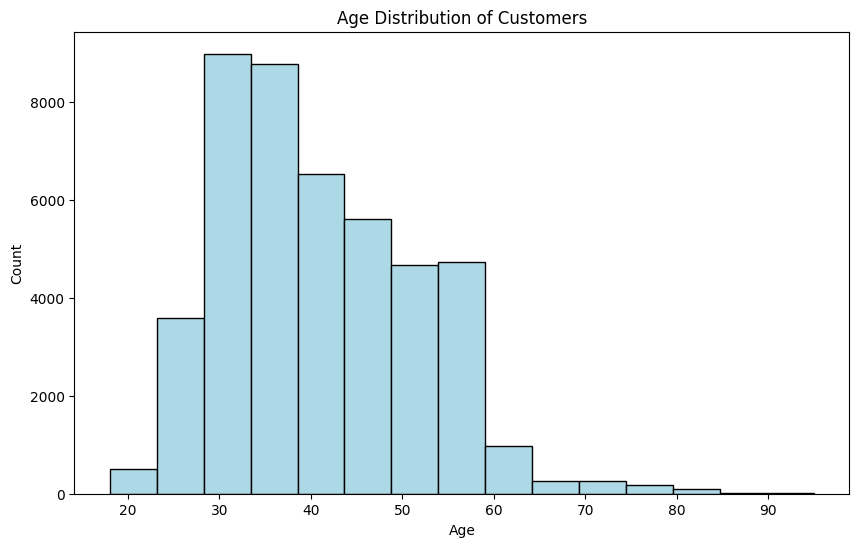

In [28]:
plt.figure(figsize=(10,6))

plt.hist(df['age'],bins = 15,edgecolor = 'k', color = "lightblue")

plt.xlabel('Age')
plt.ylabel('Count')
plt.title('Age Distribution of Customers')
plt.show()

observations:
Here, In this bar graph we can see that whats the count of each age group. highest age group is between "30-40". lowest age group is between "80-90".

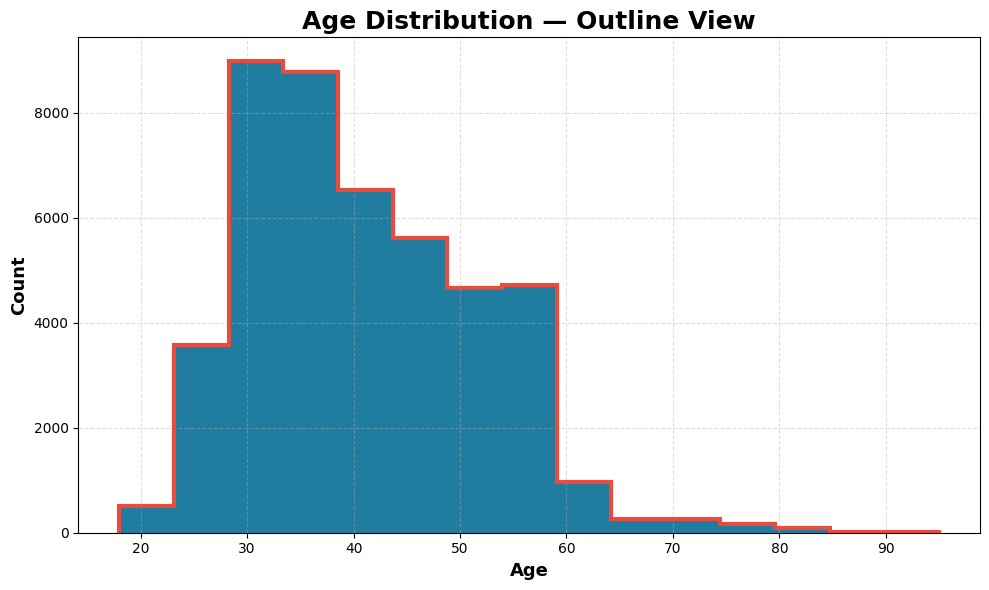

In [29]:
plt.figure(figsize=(10,6))

plt.hist(
    df['age'],
    bins=15,
    histtype='step',
    color='#E74C3C',
    linewidth=3
)

plt.fill_between(
    plt.hist(
        df['age'],
        bins=15,
        histtype='step',
        color='#E74C3C'
    )[1][:-1],
    0,
    plt.hist(
        df['age'],
        bins=15
    )[0],
    step='post',
    alpha=0.15
)

plt.xlabel(
    'Age',
    fontsize=13,
    fontweight='bold'
)

plt.ylabel(
    'Count',
    fontsize=13,
    fontweight='bold'
)

plt.title(
    'Age Distribution — Outline View',
    fontsize=18,
    fontweight='bold'
)

plt.grid(
    True,
    linestyle='--',
    alpha=0.4
)

plt.tight_layout()
plt.show()

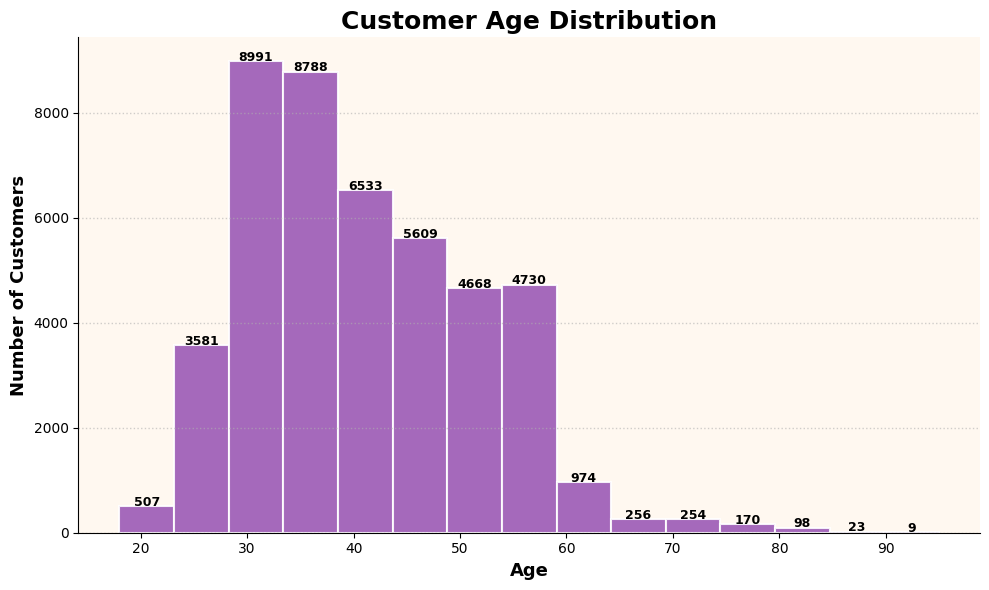

In [30]:
plt.figure(figsize=(10,6))

counts, bins, patches = plt.hist(
    df['age'],
    bins=15,
    color='#9B59B6',
    edgecolor='white',
    linewidth=1.5,
    alpha=0.9
)

plt.xlabel(
    'Age',
    fontsize=13,
    fontweight='bold'
)

plt.ylabel(
    'Number of Customers',
    fontsize=13,
    fontweight='bold'
)

plt.title(
    'Customer Age Distribution',
    fontsize=18,
    fontweight='bold'
)

# Add count above each bar
for count, patch in zip(counts, patches):
    if count > 0:
        plt.text(
            patch.get_x() + patch.get_width()/2,
            count + 2,
            f'{int(count)}',
            ha='center',
            fontsize=9,
            fontweight='bold'
        )

plt.grid(
    axis='y',
    linestyle=':',
    linewidth=1,
    alpha=0.6
)

ax = plt.gca()
ax.set_facecolor('#FFF8F0')

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.show()

2. What is the ditribution of customers by marital status?


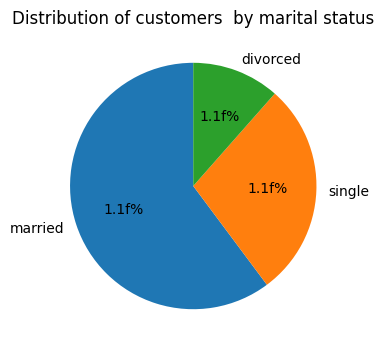

In [31]:
marital_counts = df['marital'].value_counts()

plt.figure(figsize=(8,4))

plt.pie(marital_counts, labels=marital_counts.index,
        autopct = '1.1f%%',
        startangle = 90)
plt.title('Distribution of customers  by marital status')
plt.show()

Observations:
This shows the customers marital status and we can see married are highest and divorced are the lowest.

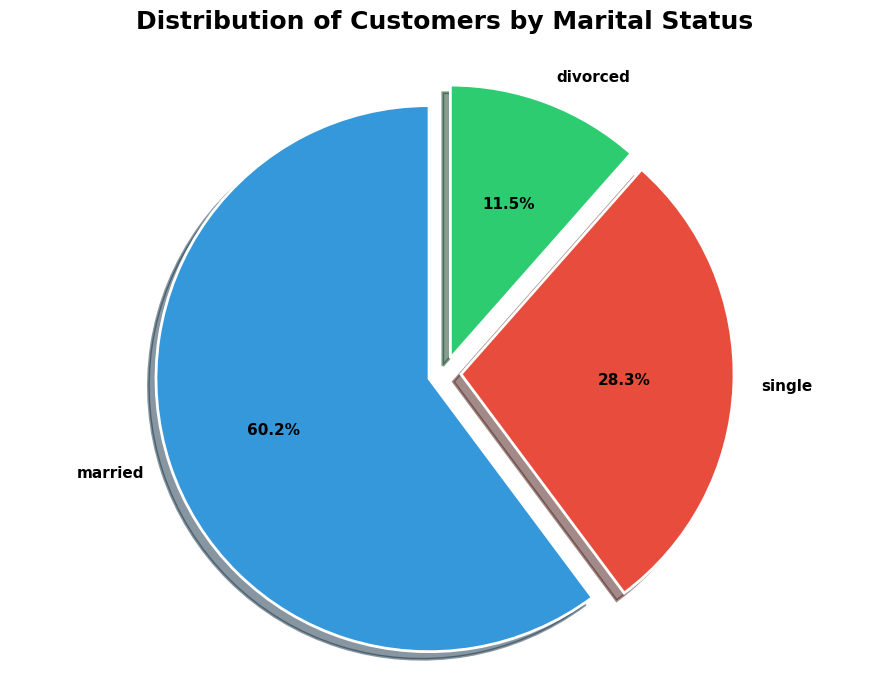

In [32]:
marital_counts = df['marital'].value_counts()

plt.figure(figsize=(9,7))

plt.pie(
    marital_counts,
    labels=marital_counts.index,
    autopct='%1.1f%%',
    startangle=90,
    explode=[0.06] * len(marital_counts),
    shadow=True,
    colors=['#3498DB', '#E74C3C', '#2ECC71'],
    wedgeprops={
        'edgecolor': 'white',
        'linewidth': 2
    },
    textprops={
        'fontsize': 11,
        'fontweight': 'bold'
    }
)

plt.title(
    'Distribution of Customers by Marital Status',
    fontsize=18,
    fontweight='bold',
    pad=20
)

plt.axis('equal')
plt.tight_layout()
plt.show()

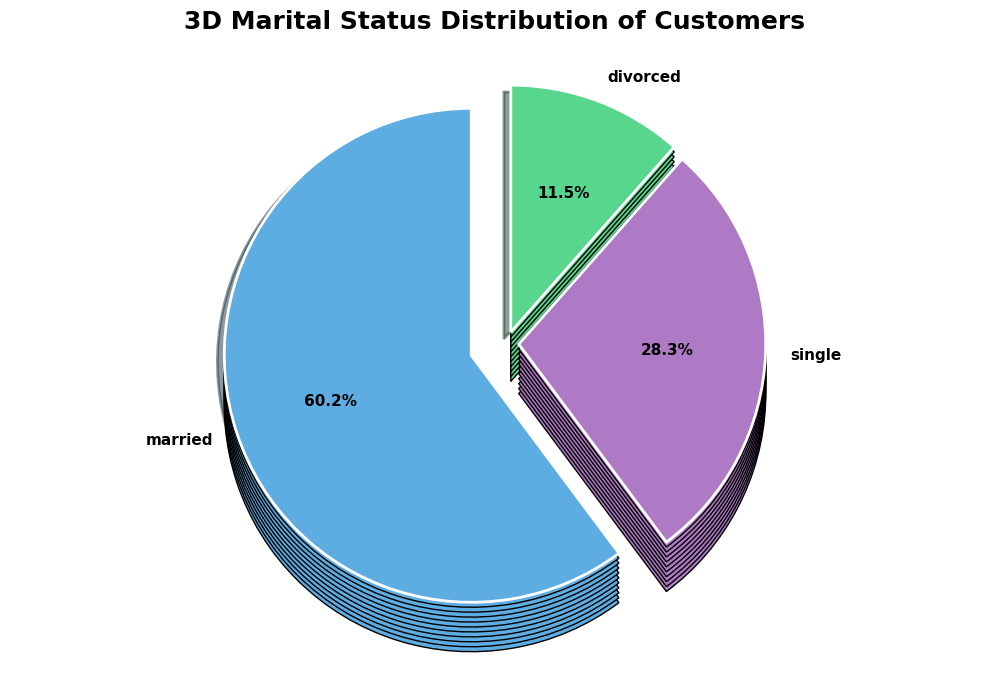

In [33]:
marital_counts = df['marital'].value_counts()

fig, ax = plt.subplots(figsize=(10,7))

colors = ['#5DADE2', '#AF7AC5', '#58D68D']

largest = marital_counts.argmax()

explode = [0.05] * len(marital_counts)
explode[largest] = 0.15

# 3D depth
for depth in range(10, 0, -1):
    ax.pie(
        marital_counts,
        startangle=90,
        colors=colors,
        explode=explode,
        radius=1,
        center=(0, -depth * 0.02),
        wedgeprops={
            'edgecolor': 'black',
            'linewidth': 1
        }
    )

# Top layer
ax.pie(
    marital_counts,
    labels=marital_counts.index,
    autopct='%1.1f%%',
    startangle=90,
    colors=colors,
    explode=explode,
    shadow=True,
    wedgeprops={
        'edgecolor': 'white',
        'linewidth': 2
    },
    textprops={
        'fontsize': 11,
        'fontweight': 'bold'
    }
)

plt.title(
    '3D Marital Status Distribution of Customers',
    fontsize=18,
    fontweight='bold',
    pad=20
)

plt.axis('equal')
plt.tight_layout()
plt.show()

3. What is the educational distribution of customers?


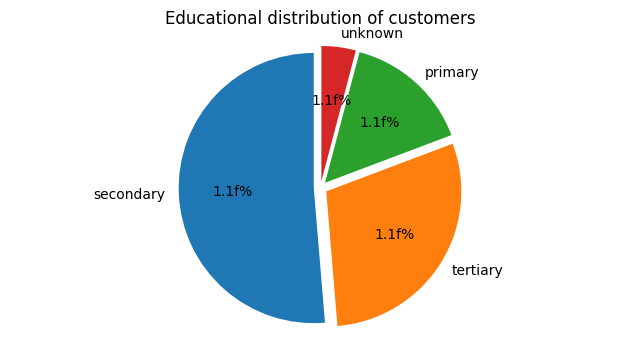

In [34]:
education_counts = df['education'].value_counts()

plt.figure(figsize=(8,4))

plt.pie(education_counts, labels=education_counts.index,
        autopct = '1.1f%%',
        startangle = 90, explode=[0.05]*len(education_counts))
plt.title('Educational distribution of customers')
plt.axis('equal')
plt.show()

Observations:
This is the educational status of the customers and we can see lowest is from unknown and highest is from secondary.

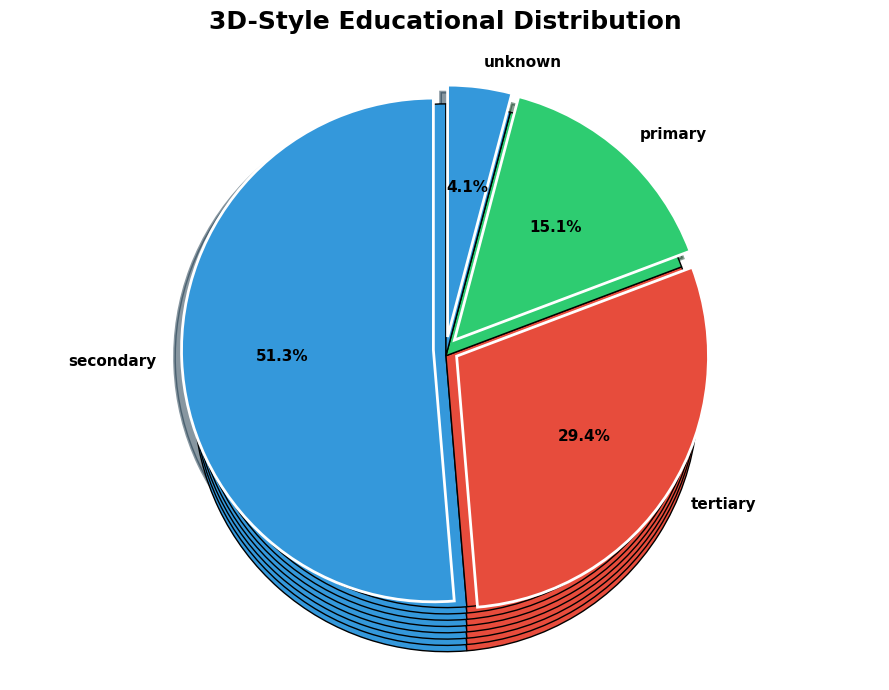

In [35]:
education_counts = df['education'].value_counts()

fig, ax = plt.subplots(figsize=(9,7))

colors = ['#3498DB', '#E74C3C', '#2ECC71']

# Create 3D depth
for depth in range(8, 0, -1):
    ax.pie(
        education_counts,
        startangle=90,
        colors=colors,
        radius=1,
        center=(0, -depth * 0.025),
        wedgeprops={
            'edgecolor': 'black',
            'linewidth': 1
        }
    )

# Top layer
wedges, texts, autotexts = ax.pie(
    education_counts,
    labels=education_counts.index,
    autopct='%1.1f%%',
    startangle=90,
    colors=colors,
    explode=[0.05] * len(education_counts),
    radius=1,
    center=(0, 0),
    shadow=True,
    wedgeprops={
        'edgecolor': 'white',
        'linewidth': 2
    },
    textprops={
        'fontsize': 11,
        'fontweight': 'bold'
    }
)

plt.title(
    '3D-Style Educational Distribution',
    fontsize=18,
    fontweight='bold',
    pad=20
)

ax.axis('equal')

plt.tight_layout()
plt.show()

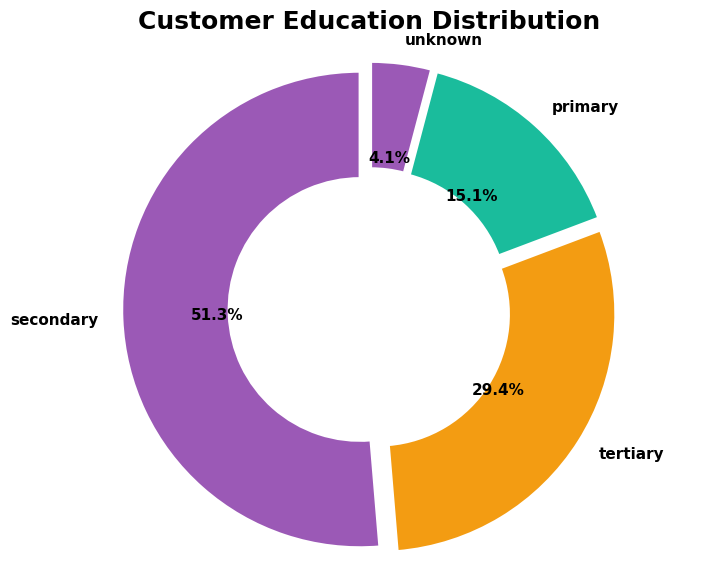

In [36]:
education_counts = df['education'].value_counts()

plt.figure(figsize=(9,7))

plt.pie(
    education_counts,
    labels=education_counts.index,
    autopct='%1.1f%%',
    startangle=90,
    colors=['#9B59B6', '#F39C12', '#1ABC9C'],
    explode=[0.04] * len(education_counts),
    wedgeprops={
        'width': 0.45,
        'edgecolor': 'white',
        'linewidth': 2
    },
    textprops={
        'fontsize': 11,
        'fontweight': 'bold'
    }
)

plt.title(
    'Customer Education Distribution',
    fontsize=18,
    fontweight='bold'
)

plt.axis('equal')
plt.show()

4. How many customers have and don't have housing loan?

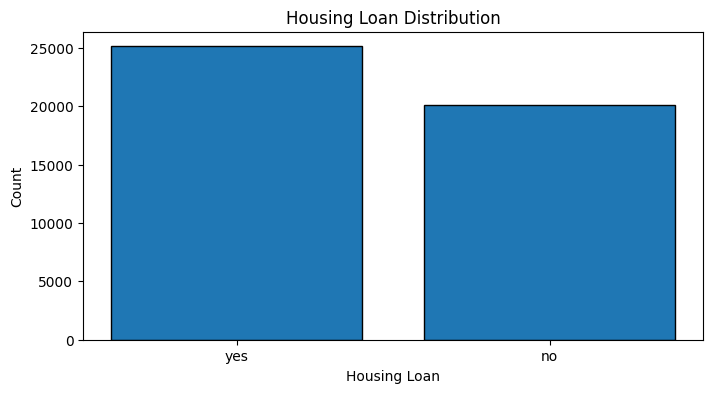

In [37]:
housing_loan_counts = df['housing loan'].value_counts()

plt.figure(figsize=(8,4))

plt.bar(housing_loan_counts.index,
        housing_loan_counts.values,
        edgecolor = "black")

plt.xlabel('Housing Loan')
plt.ylabel('Count')
plt.title('Housing Loan Distribution')
plt.show()

Observations:
Here, more customers prefer housing loan and very few of them prefer housing loan as no.

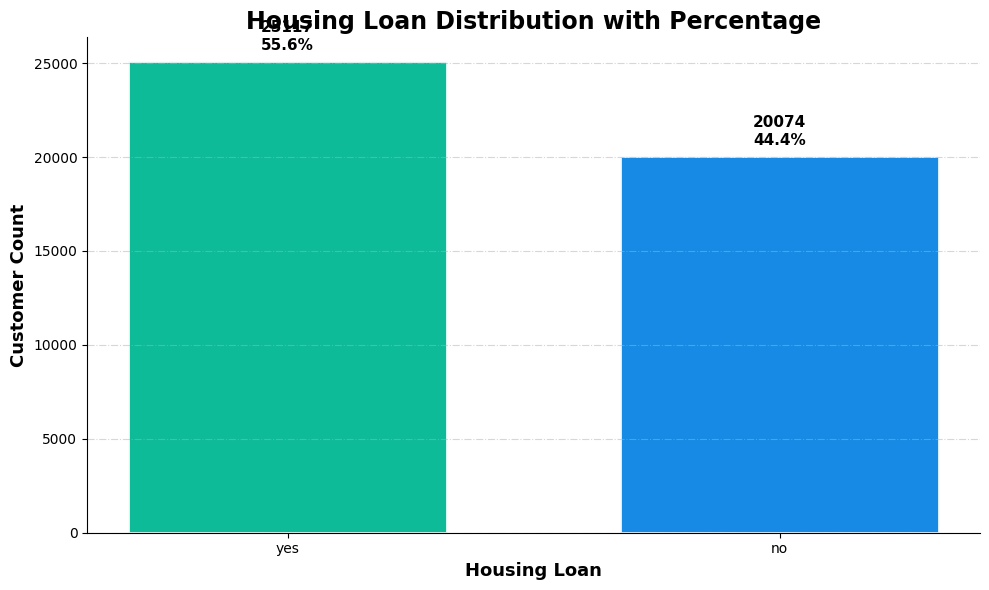

In [38]:
housing_loan_counts = df['housing loan'].value_counts()

plt.figure(figsize=(10,6))

bars = plt.bar(
    housing_loan_counts.index.astype(str),
    housing_loan_counts.values,
    color=['#00B894', '#0984E3'],
    edgecolor='white',
    linewidth=2,
    width=0.65,
    alpha=0.95
)

plt.xlabel('Housing Loan', fontsize=13, fontweight='bold')
plt.ylabel('Customer Count', fontsize=13, fontweight='bold')
plt.title(
    'Housing Loan Distribution with Percentage',
    fontsize=17,
    fontweight='bold'
)

total = housing_loan_counts.sum()

for bar in bars:
    height = bar.get_height()
    percentage = (height / total) * 100

    plt.annotate(
        f'{int(height)}\n{percentage:.1f}%',
        xy=(bar.get_x() + bar.get_width()/2, height),
        xytext=(0, 8),
        textcoords='offset points',
        ha='center',
        fontsize=11,
        fontweight='bold'
    )

plt.grid(
    axis='y',
    linestyle='-.',
    linewidth=0.8,
    alpha=0.5
)

ax = plt.gca()
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.show()

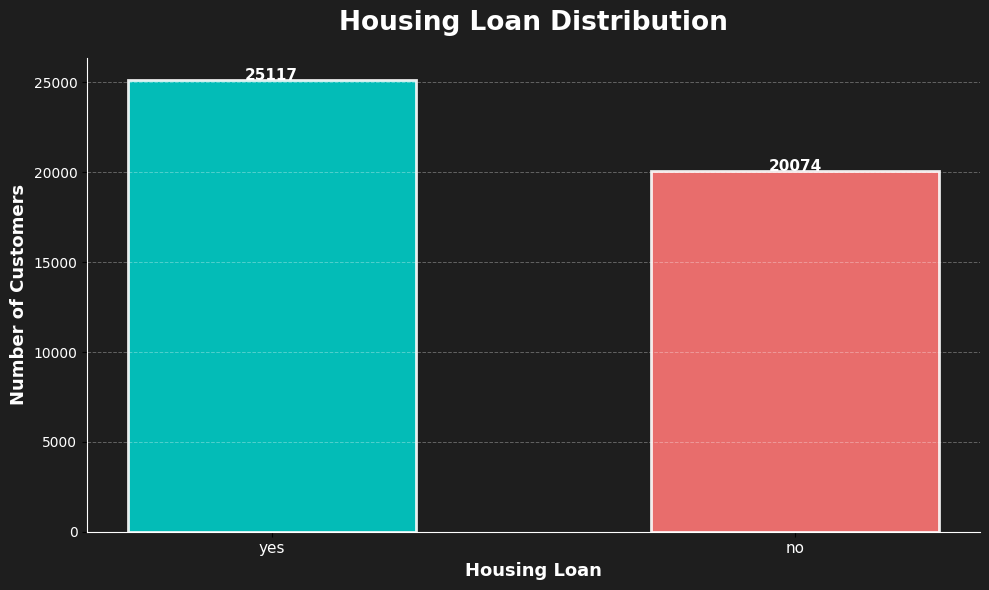

In [39]:
housing_loan_counts = df['housing loan'].value_counts()

plt.figure(figsize=(10,6))

bars = plt.bar(
    housing_loan_counts.index.astype(str),
    housing_loan_counts.values,
    color=['#00CEC9', '#FF7675'],
    edgecolor='white',
    linewidth=2,
    width=0.55,
    alpha=0.9
)

plt.xlabel(
    'Housing Loan',
    fontsize=13,
    fontweight='bold',
    color='white'
)

plt.ylabel(
    'Number of Customers',
    fontsize=13,
    fontweight='bold',
    color='white'
)

plt.title(
    'Housing Loan Distribution',
    fontsize=19,
    fontweight='bold',
    color='white',
    pad=20
)

plt.xticks(color='white', fontsize=11)
plt.yticks(color='white', fontsize=10)

plt.grid(
    axis='y',
    linestyle='--',
    linewidth=0.7,
    alpha=0.3,
    color='white'
)

# Values on bars
for bar in bars:
    height = bar.get_height()

    plt.text(
        bar.get_x() + bar.get_width()/2,
        height + 15,
        f'{int(height)}',
        ha='center',
        color='white',
        fontsize=11,
        fontweight='bold'
    )

ax = plt.gca()

ax.set_facecolor('#1E1E1E')
plt.gcf().set_facecolor('#1E1E1E')

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_color('white')
ax.spines['bottom'].set_color('white')

plt.tight_layout()
plt.show()

5. How many customers have and don't have personal loan?

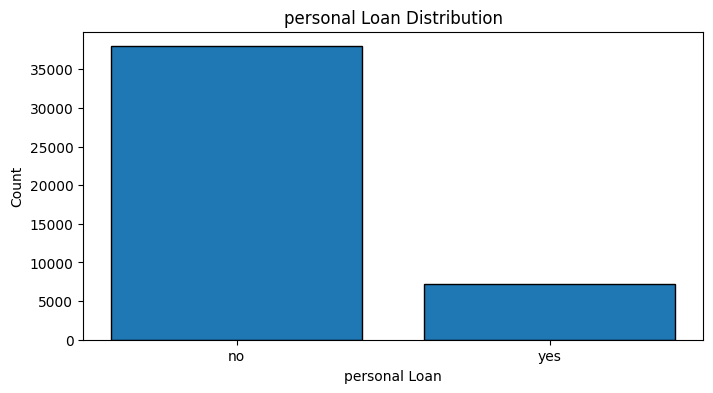

In [40]:
personal_loan_counts = df['personal loan'].value_counts()

plt.figure(figsize=(8,4))

plt.bar(personal_loan_counts.index,
        personal_loan_counts.values,
        edgecolor = "black")

plt.xlabel('personal Loan')
plt.ylabel('Count')
plt.title('personal Loan Distribution')
plt.show()

Observations:
For the personal loan customers prefer as no and very few of them want personal loan.

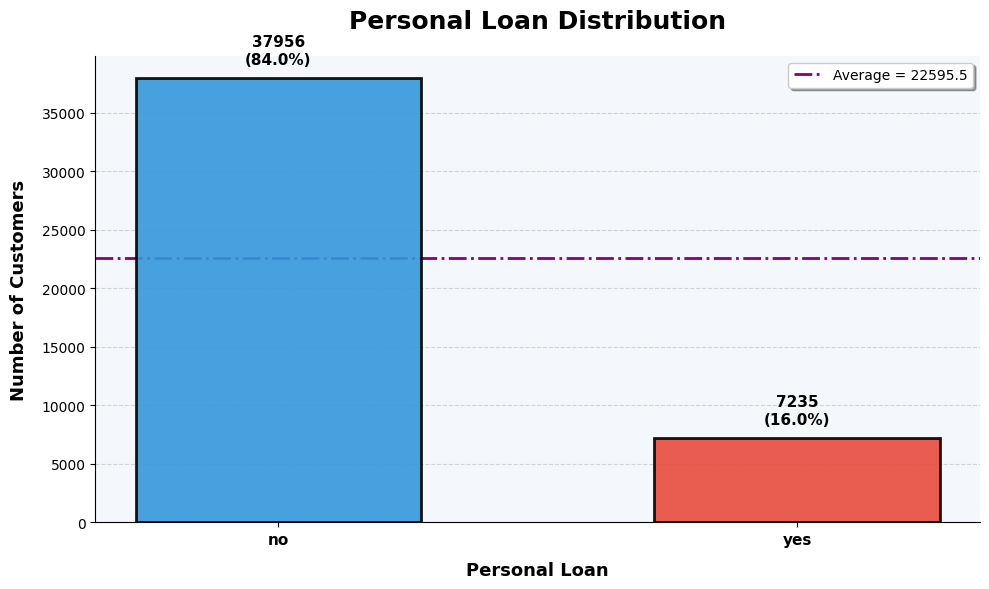

In [41]:
personal_loan_counts = df['personal loan'].value_counts()

plt.figure(figsize=(10, 6))

bars = plt.bar(
    personal_loan_counts.index,
    personal_loan_counts.values,
    color=['#3498DB', '#E74C3C'],
    edgecolor='black',
    linewidth=2,
    width=0.55,
    alpha=0.9,
    zorder=3
)

plt.xlabel(
    'Personal Loan',
    fontsize=13,
    fontweight='bold',
    labelpad=10
)

plt.ylabel(
    'Number of Customers',
    fontsize=13,
    fontweight='bold',
    labelpad=10
)

plt.title(
    'Personal Loan Distribution',
    fontsize=18,
    fontweight='bold',
    pad=20
)

plt.xticks(
    fontsize=11,
    fontweight='bold'
)

plt.yticks(fontsize=10)

# Grid
plt.grid(
    axis='y',
    linestyle='--',
    linewidth=0.8,
    alpha=0.5,
    zorder=0
)

# Add count and percentage labels
total = personal_loan_counts.sum()

for bar in bars:
    height = bar.get_height()
    percentage = (height / total) * 100

    plt.annotate(
        f'{int(height)}\n({percentage:.1f}%)',
        xy=(bar.get_x() + bar.get_width() / 2, height),
        xytext=(0, 8),
        textcoords='offset points',
        ha='center',
        va='bottom',
        fontsize=11,
        fontweight='bold'
    )

# Average reference line
average = personal_loan_counts.mean()

plt.axhline(
    average,
    color='purple',
    linestyle='-.',
    linewidth=2,
    label=f'Average = {average:.1f}'
)

# Background
ax = plt.gca()
ax.set_facecolor('#F4F7FB')

# Remove unnecessary borders
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

# Legend
plt.legend(
    loc='upper right',
    frameon=True,
    shadow=True
)

plt.tight_layout()
plt.show()

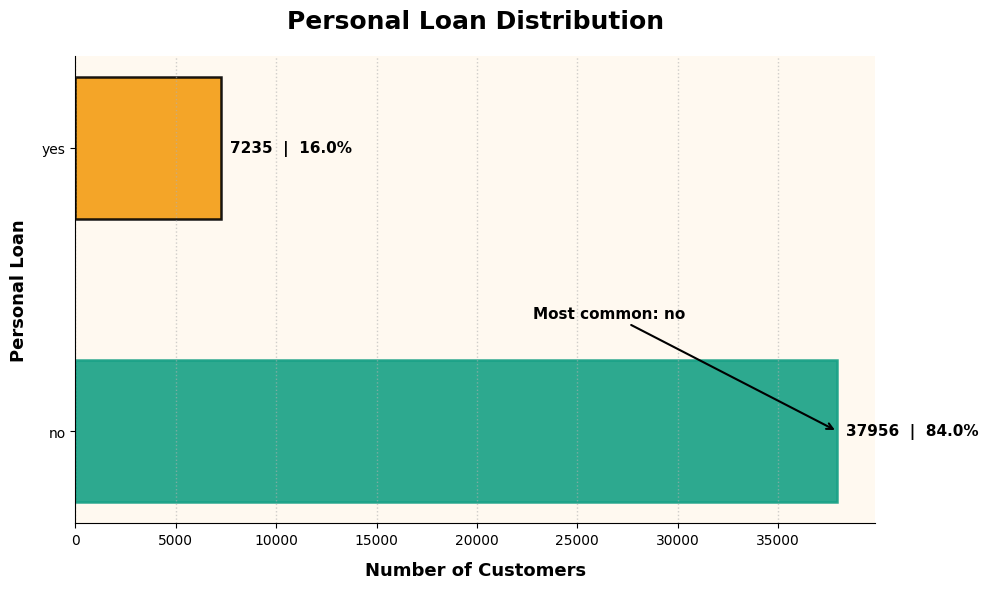

In [42]:
personal_loan_counts = df['personal loan'].value_counts()

plt.figure(figsize=(10, 6))

bars = plt.barh(
    personal_loan_counts.index.astype(str),
    personal_loan_counts.values,
    color=['#9B59B6', '#F39C12'],
    edgecolor='black',
    linewidth=1.8,
    height=0.5,
    alpha=0.9
)

plt.xlabel(
    'Number of Customers',
    fontsize=13,
    fontweight='bold',
    labelpad=10
)

plt.ylabel(
    'Personal Loan',
    fontsize=13,
    fontweight='bold',
    labelpad=10
)

plt.title(
    'Personal Loan Distribution',
    fontsize=18,
    fontweight='bold',
    pad=20
)

plt.grid(
    axis='x',
    linestyle=':',
    linewidth=1,
    alpha=0.6
)

# Add labels
total = personal_loan_counts.sum()

for bar in bars:
    width = bar.get_width()
    percentage = (width / total) * 100

    plt.text(
        width + (total * 0.01),
        bar.get_y() + bar.get_height() / 2,
        f'{int(width)}  |  {percentage:.1f}%',
        va='center',
        fontsize=11,
        fontweight='bold'
    )

# Highlight largest category
bars[0].set_color('#16A085')

# Add a border around the plotting area
ax = plt.gca()

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

ax.set_facecolor('#FFF9F0')

# Add annotation
largest_category = personal_loan_counts.index[0]
largest_value = personal_loan_counts.iloc[0]

plt.annotate(
    f'Most common: {largest_category}',
    xy=(largest_value, 0),
    xytext=(largest_value * 0.6, 0.4),
    arrowprops=dict(
        arrowstyle='->',
        color='black',
        linewidth=1.5
    ),
    fontsize=11,
    fontweight='bold'
)

plt.tight_layout()
plt.show()

6. How are customers distributed across different job categories?

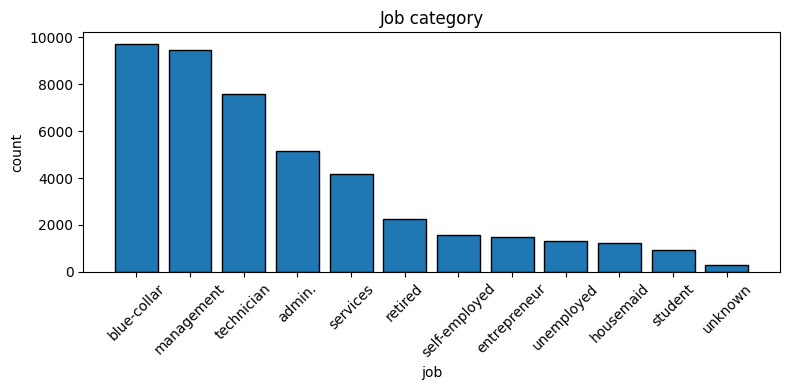

In [43]:
job_counts = df['job'].value_counts()

plt.figure(figsize=(8,4))

plt.bar(job_counts.index, job_counts.values, edgecolor = "black")

plt.xlabel('job')
plt.ylabel('count')
plt.title('Job category')
plt.xticks(rotation = 45)
plt.tight_layout()
plt.show()


Observations:
Blue-collar job are the highest and the unknown prefer less and the lowest.

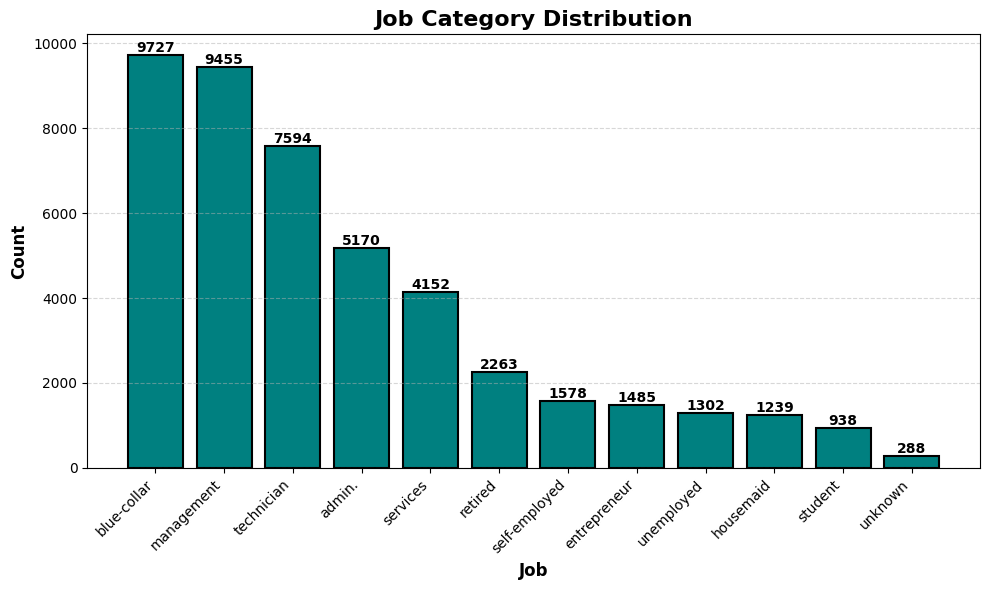

In [44]:
job_counts = df['job'].value_counts()

plt.figure(figsize=(10, 6))

bars = plt.bar(
    job_counts.index,
    job_counts.values,
    color='teal',
    edgecolor='black',
    linewidth=1.5
)

plt.xlabel(
    'Job',
    fontsize=12,
    fontweight='bold'
)

plt.ylabel(
    'Count',
    fontsize=12,
    fontweight='bold'
)

plt.title(
    'Job Category Distribution',
    fontsize=16,
    fontweight='bold'
)

plt.xticks(rotation=45, ha='right')

plt.grid(
    axis='y',
    linestyle='--',
    alpha=0.5
)

# Display values on top of bars
for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        str(int(bar.get_height())),
        ha='center',
        va='bottom',
        fontsize=10,
        fontweight='bold'
    )

plt.tight_layout()
plt.show()

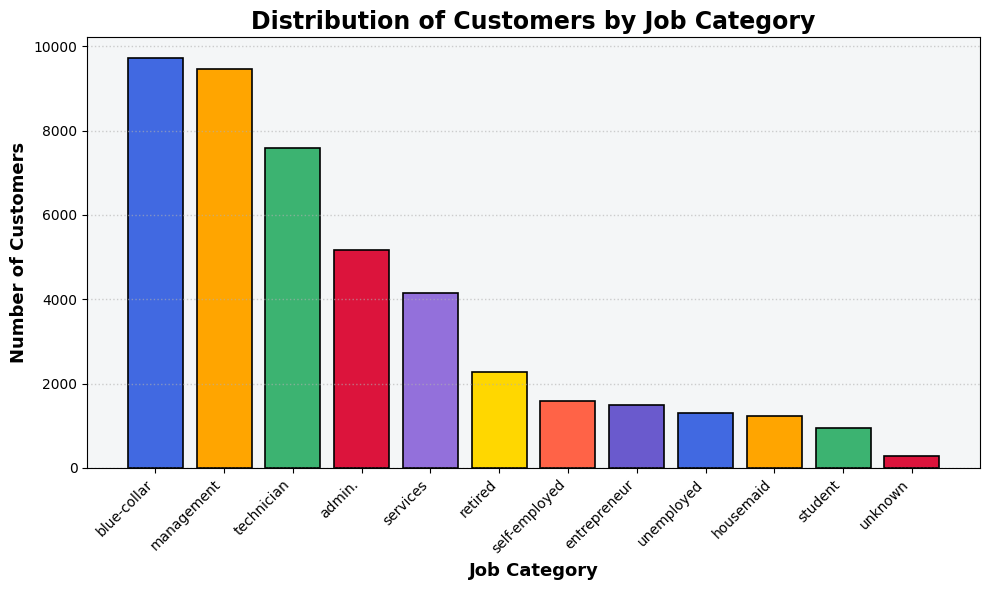

In [45]:
job_counts = df['job'].value_counts()

plt.figure(figsize=(10, 6))

colors = [
    'royalblue',
    'orange',
    'mediumseagreen',
    'crimson',
    'mediumpurple',
    'gold',
    'tomato',
    'slateblue'
]

bars = plt.bar(
    job_counts.index,
    job_counts.values,
    color=colors[:len(job_counts)],
    edgecolor='black',
    linewidth=1.2
)

plt.xlabel(
    'Job Category',
    fontsize=13,
    fontweight='bold'
)

plt.ylabel(
    'Number of Customers',
    fontsize=13,
    fontweight='bold'
)

plt.title(
    'Distribution of Customers by Job Category',
    fontsize=17,
    fontweight='bold'
)

plt.xticks(rotation=45, ha='right', fontsize=10)
plt.yticks(fontsize=10)

plt.grid(
    axis='y',
    linestyle=':',
    linewidth=1,
    alpha=0.6
)

plt.gca().set_facecolor('#F4F6F7')

plt.tight_layout()
plt.show()

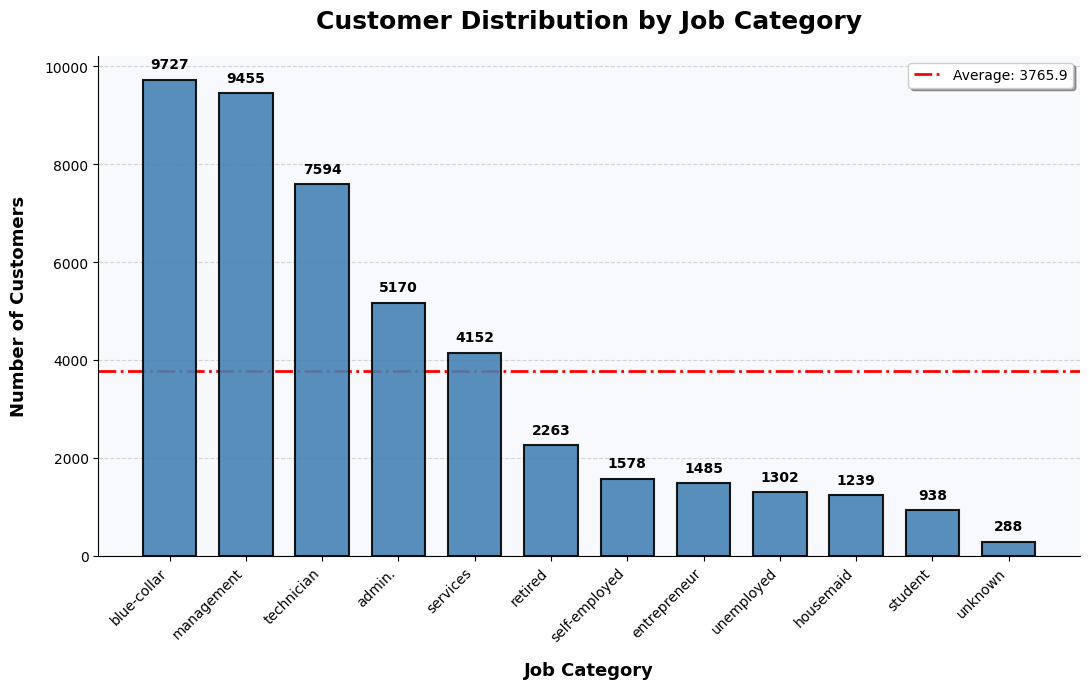

In [46]:
job_counts = df['job'].value_counts()

plt.figure(figsize=(11, 7))

bars = plt.bar(
    job_counts.index,
    job_counts.values,
    color='steelblue',
    edgecolor='black',
    linewidth=1.5,
    width=0.7,
    alpha=0.9,
    zorder=3
)

plt.xlabel(
    'Job Category',
    fontsize=13,
    fontweight='bold',
    labelpad=12
)

plt.ylabel(
    'Number of Customers',
    fontsize=13,
    fontweight='bold',
    labelpad=12
)

plt.title(
    'Customer Distribution by Job Category',
    fontsize=18,
    fontweight='bold',
    pad=20
)

plt.xticks(
    rotation=45,
    ha='right',
    fontsize=10
)

plt.yticks(fontsize=10)

# Grid behind the bars
plt.grid(
    axis='y',
    linestyle='--',
    linewidth=0.8,
    alpha=0.5,
    zorder=0
)

# Add values above bars
for bar in bars:
    height = bar.get_height()

    plt.annotate(
        f'{int(height)}',
        xy=(bar.get_x() + bar.get_width() / 2, height),
        xytext=(0, 6),
        textcoords='offset points',
        ha='center',
        va='bottom',
        fontsize=10,
        fontweight='bold'
    )

# Remove unnecessary borders
plt.gca().spines['top'].set_visible(False)
plt.gca().spines['right'].set_visible(False)

# Background
plt.gca().set_facecolor('#F7F9FC')

# Add horizontal average/reference line
average = job_counts.mean()

plt.axhline(
    average,
    color='red',
    linestyle='-.',
    linewidth=2,
    label=f'Average: {average:.1f}'
)

plt.legend(
    loc='upper right',
    frameon=True,
    shadow=True
)

plt.tight_layout()
plt.show()

##Bi-Variate Analysis

7. Is there a relationship between customer age and salary?

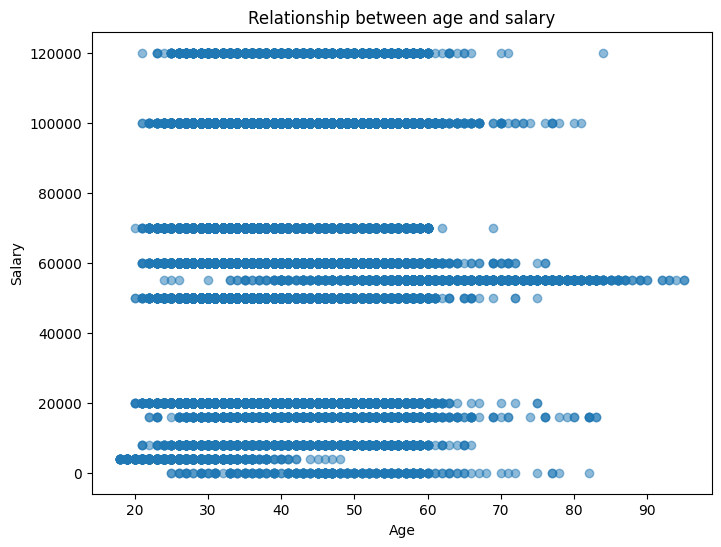

In [47]:
plt.figure(figsize=(8,6))

plt.scatter(df['age'],df['salary'],alpha = 0.5)

plt.xlabel('Age')
plt.ylabel('Salary')
plt.title('Relationship between age and salary')
plt.show()

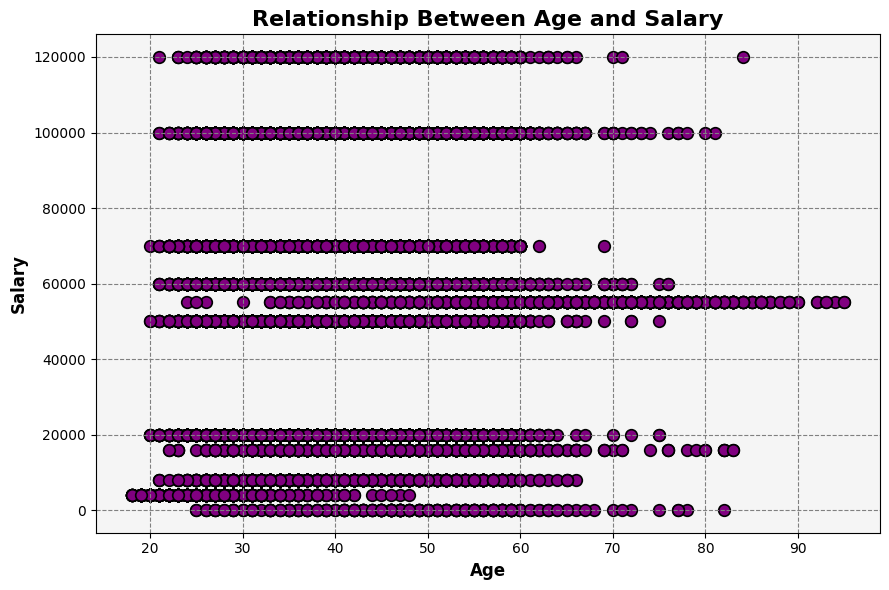

In [48]:
plt.figure(figsize=(9, 6))

plt.scatter(
    df['age'],
    df['salary'],
    color='purple',
    marker='o',
    s=70,
    edgecolors='black',
    linewidths=1.2
)

plt.xlabel(
    'Age',
    fontsize=12,
    fontweight='bold'
)

plt.ylabel(
    'Salary',
    fontsize=12,
    fontweight='bold'
)

plt.title(
    'Relationship Between Age and Salary',
    fontsize=16,
    fontweight='bold'
)

plt.xticks(fontsize=10)
plt.yticks(fontsize=10)

plt.grid(
    True,
    linestyle='--',
    linewidth=0.8,
    color='gray'
)

plt.gca().set_facecolor('#F5F5F5')

plt.tight_layout()
plt.show()

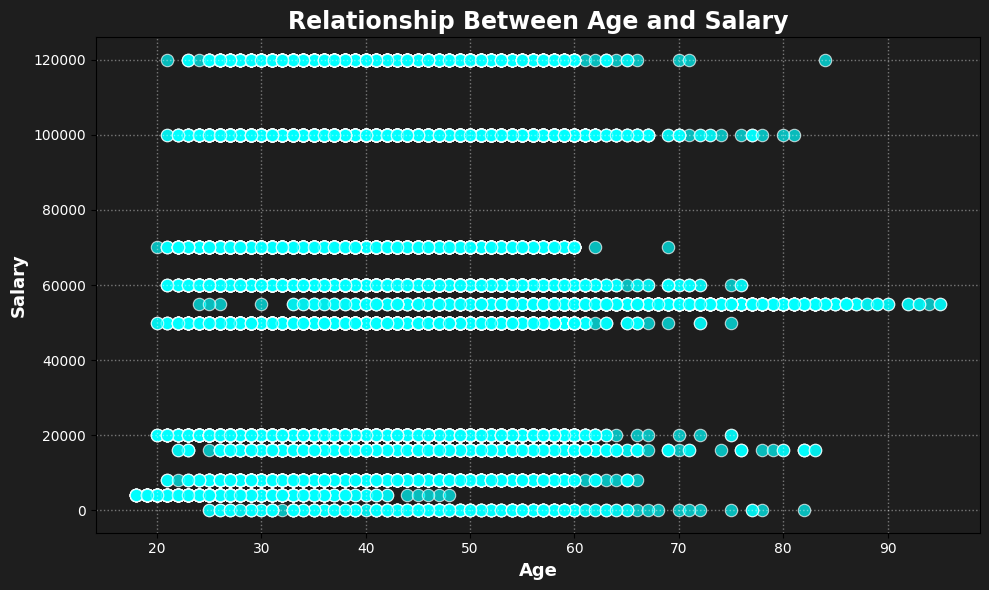

In [49]:
plt.figure(figsize=(10, 6))

plt.scatter(
    df['age'],
    df['salary'],
    color='cyan',
    alpha=0.7,
    s=80,
    edgecolor='white',
    linewidth=0.8
)

plt.xlabel(
    'Age',
    fontsize=13,
    fontweight='bold',
    color='white'
)

plt.ylabel(
    'Salary',
    fontsize=13,
    fontweight='bold',
    color='white'
)

plt.title(
    'Relationship Between Age and Salary',
    fontsize=17,
    fontweight='bold',
    color='white'
)

plt.xticks(color='white')
plt.yticks(color='white')

plt.grid(
    linestyle=':',
    linewidth=1,
    alpha=0.4,
    color='white'
)

plt.gca().set_facecolor('#1E1E1E')
plt.gcf().set_facecolor('#1E1E1E')

plt.tight_layout()
plt.show()

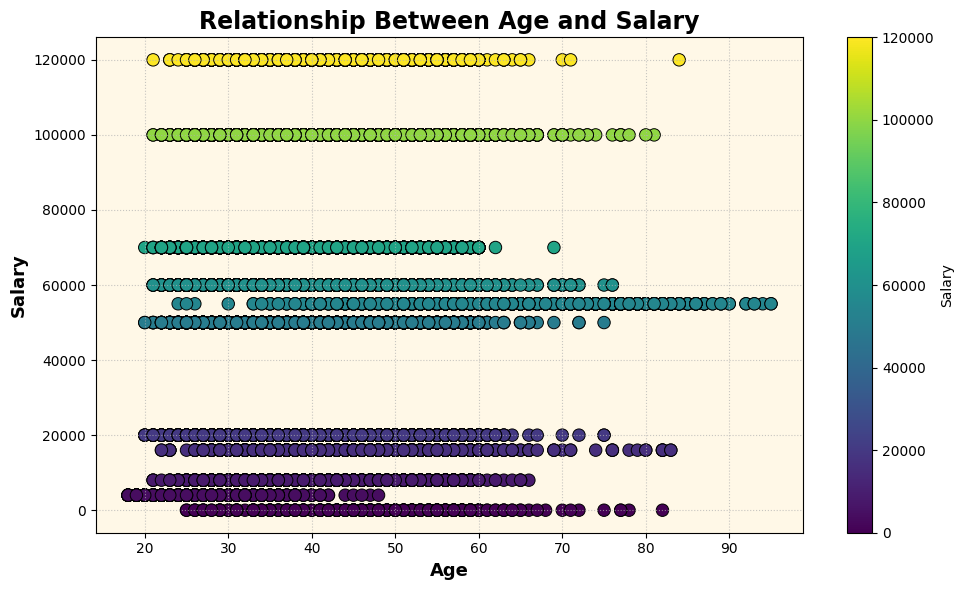

In [50]:
plt.figure(figsize=(10, 6))

plt.scatter(
    df['age'],
    df['salary'],
    c=df['salary'],
    cmap='viridis',
    s=80,
    marker='o',
    edgecolors='black',
    linewidths=0.7
)

plt.xlabel(
    'Age',
    fontsize=13,
    fontweight='bold'
)

plt.ylabel(
    'Salary',
    fontsize=13,
    fontweight='bold'
)

plt.title(
    'Relationship Between Age and Salary',
    fontsize=17,
    fontweight='bold'
)

plt.colorbar(label='Salary')

plt.grid(
    axis='both',
    linestyle=':',
    linewidth=0.8,
    alpha=0.7
)

plt.gca().set_facecolor('#FFF8E7')

plt.tight_layout()
plt.show()

8. Does salary differ between customers who respond 'yes' and'no'?

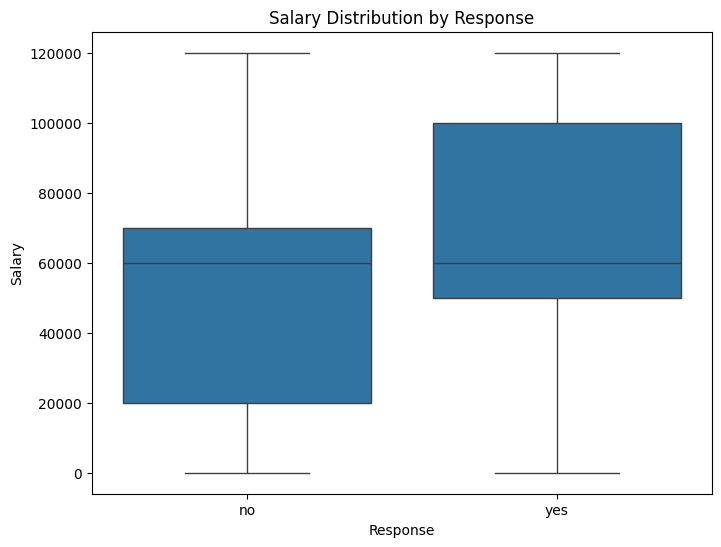

In [51]:
plt.figure(figsize=(8,6))

sns.boxplot(x='response', y='salary', data=df)

plt.xlabel('Response')
plt.ylabel('Salary')
plt.title('Salary Distribution by Response')
plt.show()

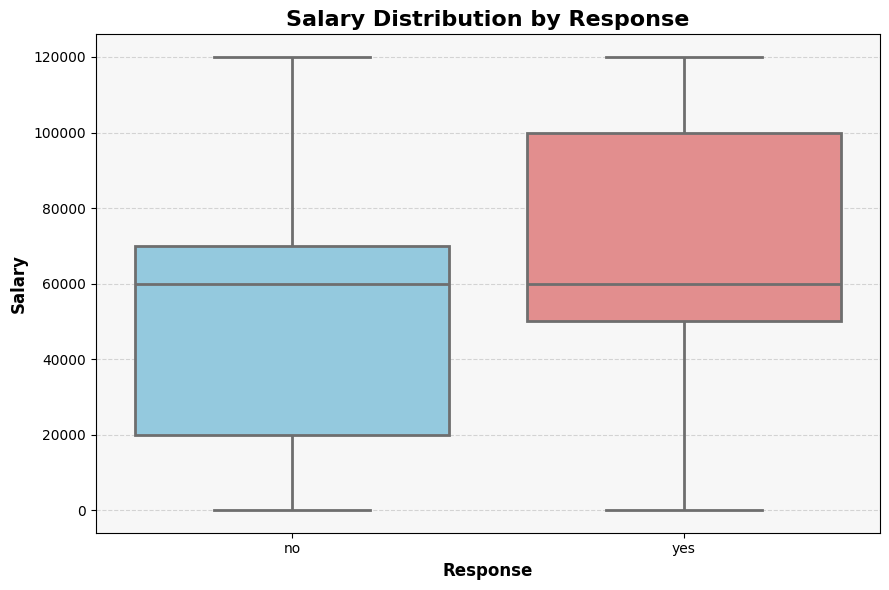

In [52]:
plt.figure(figsize=(9, 6))

sns.boxplot(
    x='response',
    y='salary',
    data=df,
    palette=['skyblue', 'lightcoral'],
    linewidth=2,
    fliersize=5
)

plt.xlabel('Response', fontsize=12, fontweight='bold')
plt.ylabel('Salary', fontsize=12, fontweight='bold')

plt.title(
    'Salary Distribution by Response',
    fontsize=16,
    fontweight='bold'
)

plt.grid(
    axis='y',
    linestyle='--',
    alpha=0.5
)

plt.gca().set_facecolor('#f7f7f7')

plt.tight_layout()
plt.show()

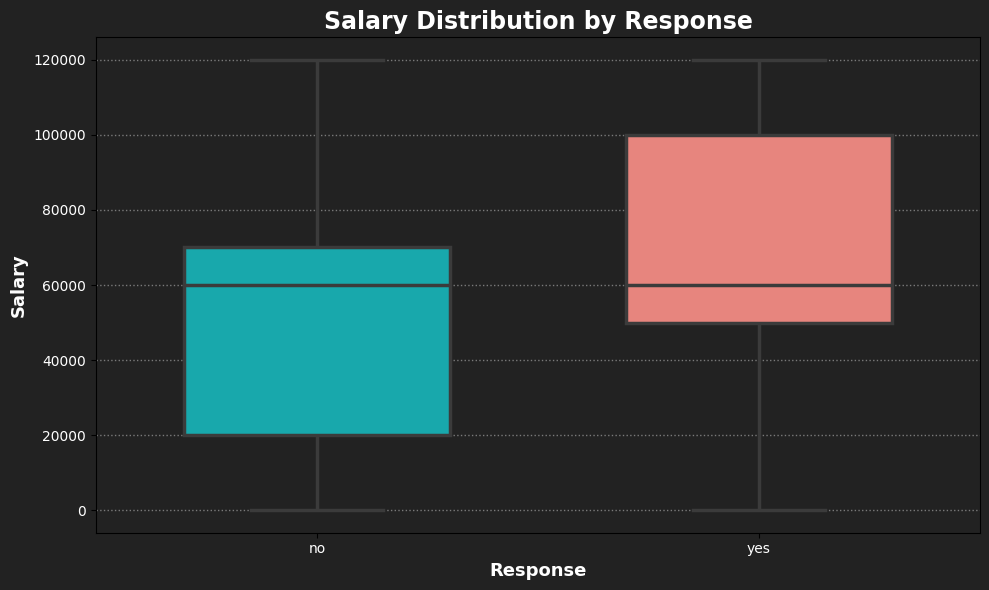

In [53]:
plt.figure(figsize=(10, 6))

ax = sns.boxplot(
    x='response',
    y='salary',
    data=df,
    palette=['#00BFC4', '#F8766D'],
    linewidth=2.5,
    width=0.6,
    fliersize=6
)

plt.xlabel(
    'Response',
    fontsize=13,
    fontweight='bold',
    color='white'
)

plt.ylabel(
    'Salary',
    fontsize=13,
    fontweight='bold',
    color='white'
)

plt.title(
    'Salary Distribution by Response',
    fontsize=17,
    fontweight='bold',
    color='white'
)

plt.xticks(color='white')
plt.yticks(color='white')

plt.grid(
    axis='y',
    linestyle=':',
    linewidth=1,
    alpha=0.4,
    color='white'
)

ax.set_facecolor('#222222')
plt.gcf().set_facecolor('#222222')

plt.tight_layout()
plt.show()

###Boxplot

25% -- Q1

50% -- Q2

75% -- Q3

9. Does the number of customers who responded differ between customers with and without personal loans?

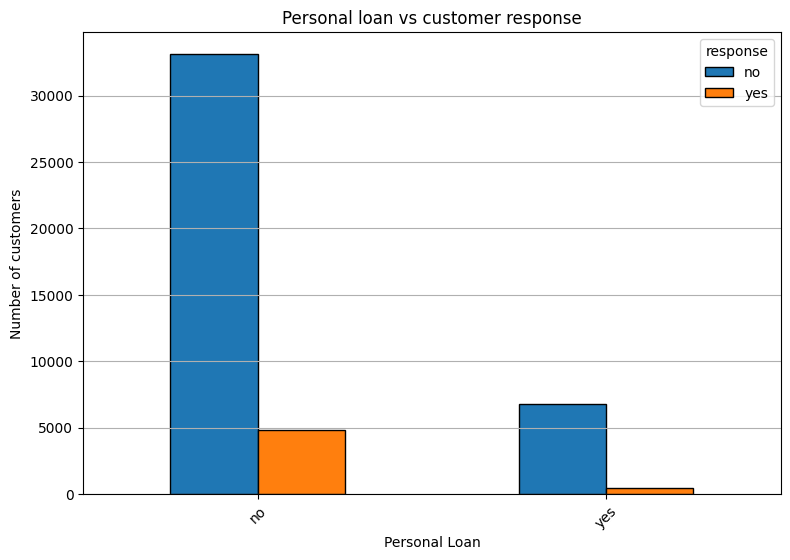

In [54]:
loan_response = pd.crosstab(df['personal loan'], df['response'])

loan_response.plot(kind = 'bar',figsize=(9,6),edgecolor = 'black')

plt.xlabel('Personal Loan')
plt.ylabel('Number of customers')
plt.title('Personal loan vs customer response')

plt.xticks(rotation = 45)

plt.legend(title = "response")
plt.grid(axis = 'y', linestyle = '-')
plt.show()


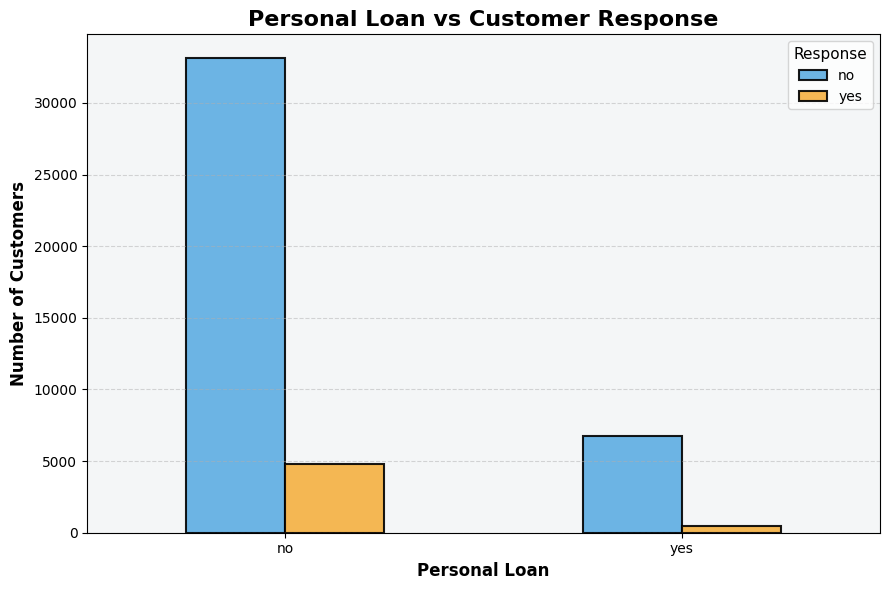

In [55]:
loan_response = pd.crosstab(df['personal loan'], df['response'])

loan_response.plot(
    kind='bar',
    figsize=(9, 6),
    edgecolor='black',
    color=['#5DADE2', '#F5B041'],
    linewidth=1.5,
    alpha=0.9
)

plt.xlabel('Personal Loan', fontsize=12, fontweight='bold')
plt.ylabel('Number of Customers', fontsize=12, fontweight='bold')

plt.title(
    'Personal Loan vs Customer Response',
    fontsize=16,
    fontweight='bold'
)

plt.xticks(rotation=0, fontsize=10)
plt.yticks(fontsize=10)

plt.legend(
    title='Response',
    title_fontsize=11,
    fontsize=10
)

plt.grid(
    axis='y',
    linestyle='--',
    linewidth=0.8,
    alpha=0.5
)

plt.gca().set_facecolor('#F4F6F7')

plt.tight_layout()
plt.show()

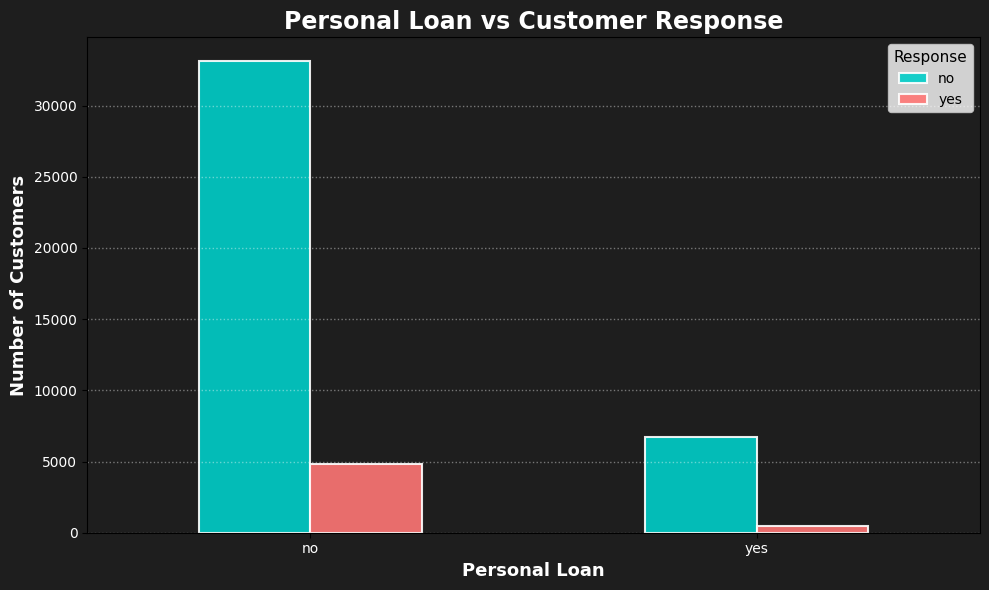

In [56]:
loan_response = pd.crosstab(df['personal loan'], df['response'])

ax = loan_response.plot(
    kind='bar',
    figsize=(10, 6),
    edgecolor='white',
    color=['#00CEC9', '#FF7675'],
    linewidth=1.5,
    alpha=0.9
)

plt.xlabel(
    'Personal Loan',
    fontsize=13,
    fontweight='bold',
    color='white'
)

plt.ylabel(
    'Number of Customers',
    fontsize=13,
    fontweight='bold',
    color='white'
)

plt.title(
    'Personal Loan vs Customer Response',
    fontsize=17,
    fontweight='bold',
    color='white'
)

plt.xticks(rotation=0, color='white')
plt.yticks(color='white')

plt.legend(
    title='Response',
    title_fontsize=11,
    fontsize=10
)

plt.grid(
    axis='y',
    linestyle=':',
    linewidth=1,
    alpha=0.4,
    color='white'
)

ax.set_facecolor('#1E1E1E')
plt.gcf().set_facecolor('#1E1E1E')

plt.tight_layout()
plt.show()

10. Does having a housing loan relate to customer reponse?

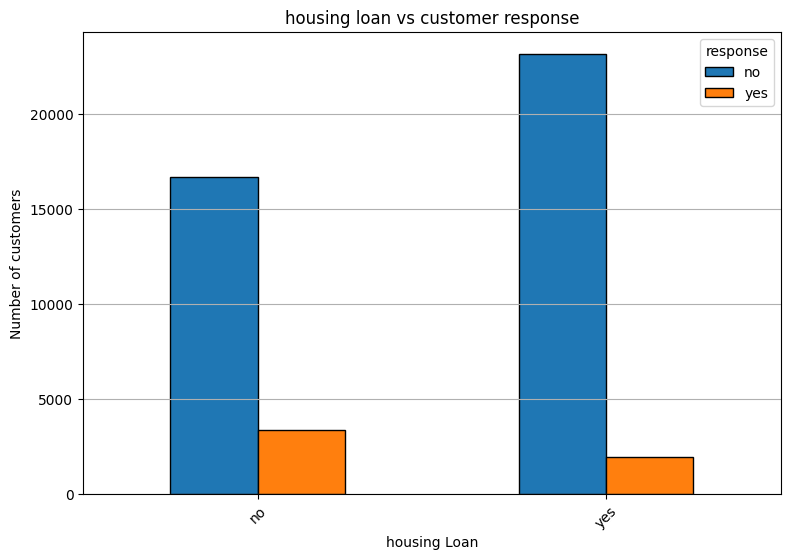

In [57]:
housing_response = pd.crosstab(df['housing loan'], df['response'])

housing_response.plot(kind = 'bar',figsize=(9,6),edgecolor = 'black')

plt.xlabel('housing Loan')
plt.ylabel('Number of customers')
plt.title('housing loan vs customer response')

plt.xticks(rotation = 45)

plt.legend(title = "response")
plt.grid(axis = 'y', linestyle = '-')
plt.show()


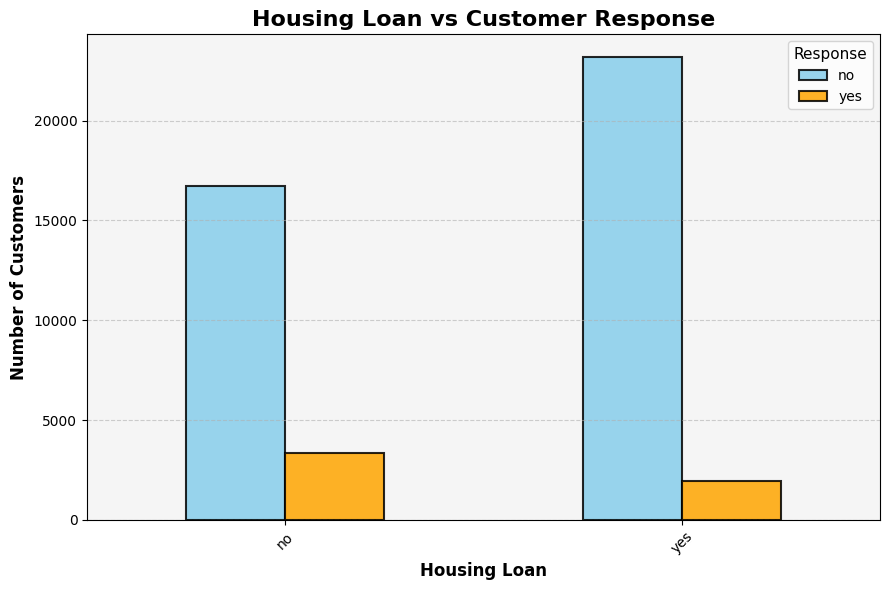

In [58]:
housing_response = pd.crosstab(df['housing loan'], df['response'])

housing_response.plot(
    kind='bar',
    figsize=(9, 6),
    edgecolor='black',
    color=['skyblue', 'orange'],
    alpha=0.85,
    linewidth=1.5
)

plt.xlabel('Housing Loan', fontsize=12, fontweight='bold')
plt.ylabel('Number of Customers', fontsize=12, fontweight='bold')

plt.title(
    'Housing Loan vs Customer Response',
    fontsize=16,
    fontweight='bold'
)

plt.xticks(rotation=45, fontsize=10)
plt.yticks(fontsize=10)

plt.legend(
    title="Response",
    title_fontsize=11,
    fontsize=10
)

plt.grid(
    axis='y',
    linestyle='--',
    linewidth=0.8,
    alpha=0.6
)

plt.gca().set_facecolor('#f5f5f5')
plt.gcf().set_facecolor('white')

plt.tight_layout()
plt.show()

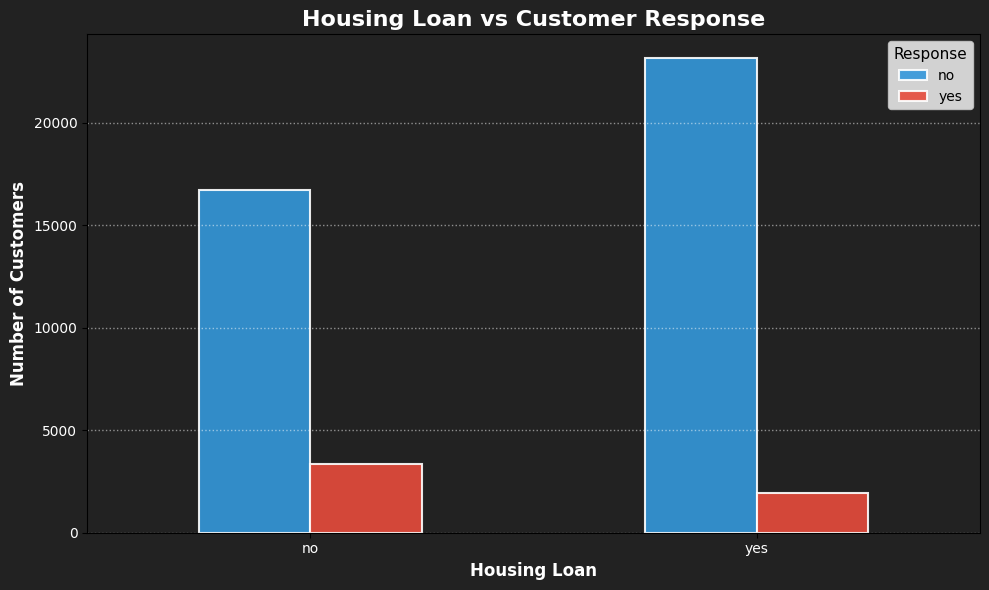

In [59]:
housing_response = pd.crosstab(df['housing loan'], df['response'])

ax = housing_response.plot(
    kind='bar',
    figsize=(10, 6),
    color=['#3498DB', '#E74C3C'],
    edgecolor='white',
    linewidth=1.5,
    alpha=0.9
)

plt.xlabel('Housing Loan', fontsize=12, fontweight='bold', color='white')
plt.ylabel('Number of Customers', fontsize=12, fontweight='bold', color='white')

plt.title(
    'Housing Loan vs Customer Response',
    fontsize=16,
    fontweight='bold',
    color='white'
)

plt.xticks(rotation=0, color='white')
plt.yticks(color='white')

plt.legend(
    title='Response',
    title_fontsize=11,
    fontsize=10
)

plt.grid(
    axis='y',
    linestyle=':',
    linewidth=1,
    alpha=0.5,
    color='white'
)

ax.set_facecolor('#222222')
plt.gcf().set_facecolor('#222222')

plt.tight_layout()
plt.show()

## Multi variate analysis

11. which job category have the higest positive response rate?

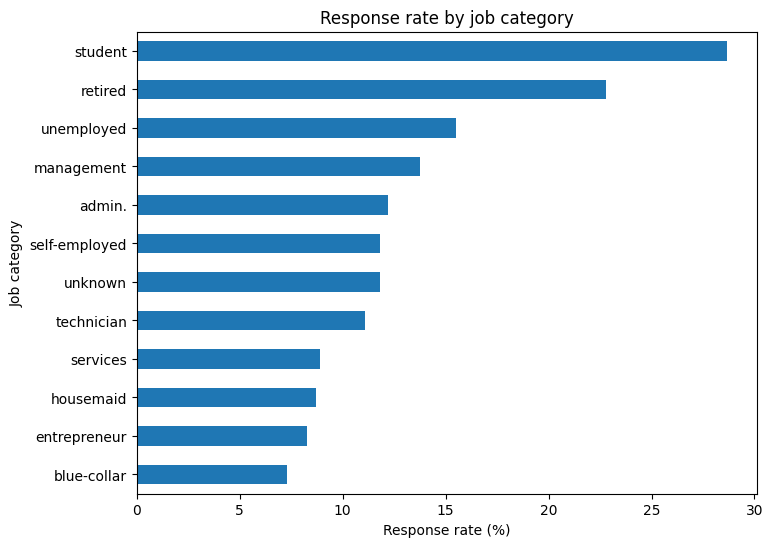

In [67]:
job_response = pd.crosstab(df['job'], df['response'],normalize = 'index') * 100

job_response['yes'].sort_values().plot(kind = 'barh',figsize =(8,6))

plt.xlabel('Response rate (%)')
plt.ylabel('Job category')
plt.title('Response rate by job category')

plt.show()

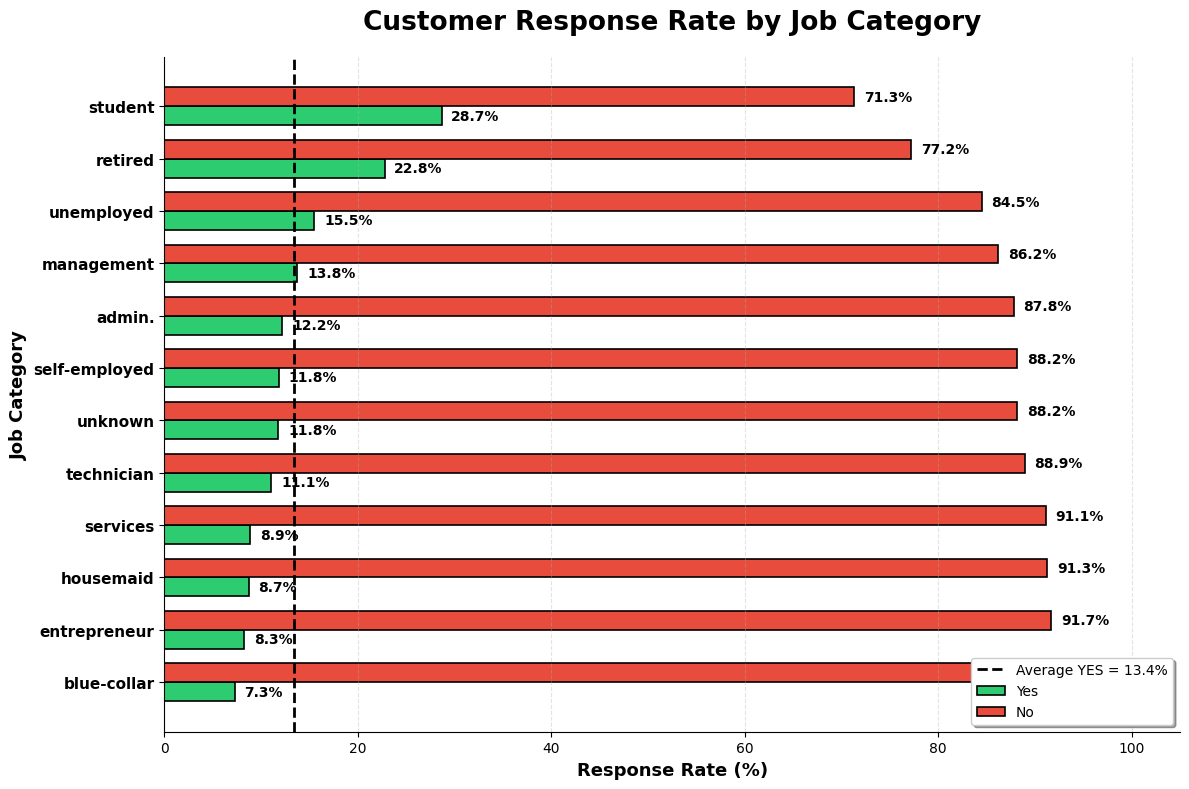

In [61]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# Calculate response rate
job_response = pd.crosstab(
    df['job'],
    df['response'],
    normalize='index'
) * 100

# Sort by YES response rate
job_response = job_response.sort_values('yes')

jobs = job_response.index
yes_rate = job_response['yes']
no_rate = job_response['no']

# Create figure
fig, ax = plt.subplots(figsize=(12, 8))

y = np.arange(len(jobs))
height = 0.36

# YES bars
bars_yes = ax.barh(
    y - height/2,
    yes_rate,
    height,
    label='Yes',
    color='#2ECC71',
    edgecolor='black',
    linewidth=1.2
)

# NO bars
bars_no = ax.barh(
    y + height/2,
    no_rate,
    height,
    label='No',
    color='#E74C3C',
    edgecolor='black',
    linewidth=1.2
)

# Add percentage labels
for bars in [bars_yes, bars_no]:
    for bar in bars:
        width = bar.get_width()

        ax.text(
            width + 1,
            bar.get_y() + bar.get_height()/2,
            f'{width:.1f}%',
            va='center',
            fontsize=10,
            fontweight='bold'
        )

# Average YES response rate
average_yes = yes_rate.mean()

ax.axvline(
    average_yes,
    color='black',
    linestyle='--',
    linewidth=2,
    label=f'Average YES = {average_yes:.1f}%'
)

# Labels
ax.set_yticks(y)
ax.set_yticklabels(
    jobs,
    fontsize=11,
    fontweight='bold'
)

ax.set_xlabel(
    'Response Rate (%)',
    fontsize=13,
    fontweight='bold'
)

ax.set_ylabel(
    'Job Category',
    fontsize=13,
    fontweight='bold'
)

ax.set_title(
    'Customer Response Rate by Job Category',
    fontsize=19,
    fontweight='bold',
    pad=20
)

# Percentage scale
ax.set_xlim(0, 105)

# Grid
ax.grid(
    axis='x',
    linestyle='--',
    alpha=0.35
)

# Remove unnecessary borders
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

# Legend
ax.legend(
    loc='lower right',
    frameon=True,
    shadow=True
)

plt.tight_layout()
plt.show()

In [62]:
import plotly.graph_objects as go
import numpy as np

job_response = pd.crosstab(
    df['job'],
    df['response'],
    normalize='index'
) * 100

jobs = list(job_response.index)

z = job_response[['yes', 'no']].values

fig = go.Figure(
    data=[
        go.Surface(
            z=z,
            x=np.arange(len(jobs)),
            y=['YES', 'NO'],
            text=np.round(z, 1),
            hovertemplate=
                'Job: %{x}<br>' +
                'Response: %{y}<br>' +
                'Rate: %{z:.1f}%<extra></extra>'
        )
    ]
)

fig.update_layout(
    title='3D Response Rate Surface by Job Category',

    scene=dict(
        xaxis=dict(
            title='Job Category',
            tickvals=np.arange(len(jobs)),
            ticktext=jobs
        ),

        yaxis=dict(
            title='Response'
        ),

        zaxis=dict(
            title='Response Rate (%)'
        ),

        camera=dict(
            eye=dict(
                x=1.7,
                y=1.7,
                z=1.3
            )
        )
    ),

    width=1200,
    height=800
)

fig.show()

12. how does customers response vary by month ?

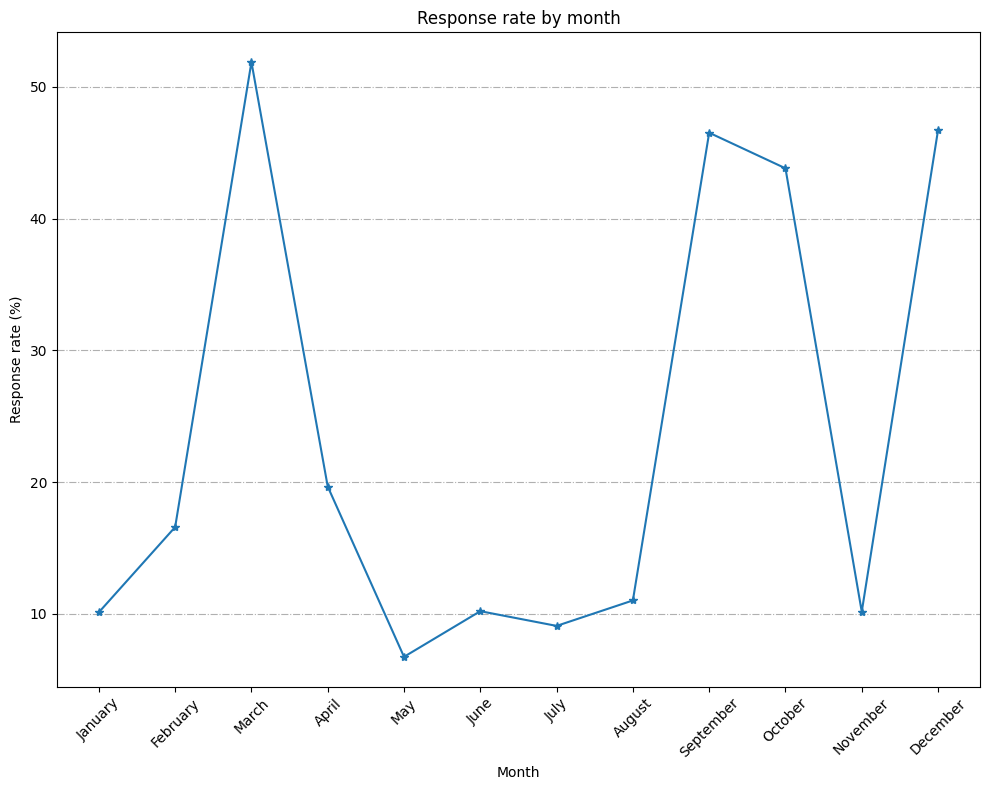

In [68]:
month_response = pd.crosstab(df['month_name'], df['response'],normalize = 'index') * 100

month_order = ['January', 'February', 'March', 'April', 'May', 'June', 'July', 'August', 'September', 'October', 'November', 'December']
monthly_response = month_response.reindex(month_order)

plt.figure(figsize=(10, 8))
plt.plot(monthly_response.index,monthly_response['yes'],marker = '*')  #'*' , '^' , '+'

plt.xlabel('Month')
plt.ylabel('Response rate (%)')
plt.title('Response rate by month')

plt.xticks(rotation=45)
plt.grid(axis='y', linestyle='-.')
plt.tight_layout()
plt.show()

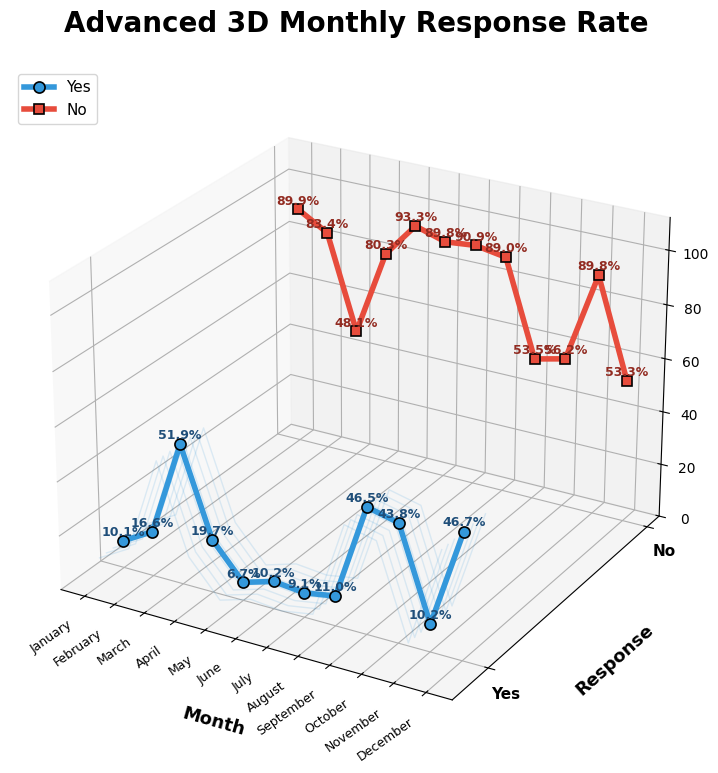

In [64]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Calculate response rate
month_response = pd.crosstab(
    df['month_name'],
    df['response'],
    normalize='index'
) * 100

# Month order
month_order = [
    'January', 'February', 'March', 'April',
    'May', 'June', 'July', 'August',
    'September', 'October', 'November', 'December'
]

monthly_response = month_response.reindex(month_order)

# X positions
x = np.arange(len(monthly_response))

# Create 3D figure
fig = plt.figure(figsize=(16, 9))
ax = fig.add_subplot(111, projection='3d')

# Y positions for depth
y_yes = np.zeros(len(x))
y_no = np.ones(len(x)) * 1.2

# Response values
yes_values = monthly_response['yes'].values
no_values = monthly_response['no'].values

# ------------------------------------------------
# BACKGROUND / DEPTH LAYERS
# ------------------------------------------------

for depth in np.linspace(-0.15, 0.15, 8):

    ax.plot(
        x,
        y_yes + depth,
        yes_values,
        color='#3498DB',
        linewidth=1,
        alpha=0.15
    )

# ------------------------------------------------
# MAIN YES LINE
# ------------------------------------------------

ax.plot(
    x,
    y_yes,
    yes_values,
    color='#3498DB',
    linewidth=4,
    marker='o',
    markersize=8,
    markeredgecolor='black',
    markeredgewidth=1.2,
    label='Yes'
)

# ------------------------------------------------
# MAIN NO LINE
# ------------------------------------------------

ax.plot(
    x,
    y_no,
    no_values,
    color='#E74C3C',
    linewidth=4,
    marker='s',
    markersize=7,
    markeredgecolor='black',
    markeredgewidth=1.2,
    label='No'
)

# ------------------------------------------------
# VALUE LABELS
# ------------------------------------------------

for i in range(len(x)):

    ax.text(
        x[i],
        y_yes[i],
        yes_values[i] + 2,
        f'{yes_values[i]:.1f}%',
        fontsize=9,
        fontweight='bold',
        color='#1F4E79',
        ha='center'
    )

    ax.text(
        x[i],
        y_no[i],
        no_values[i] + 2,
        f'{no_values[i]:.1f}%',
        fontsize=9,
        fontweight='bold',
        color='#922B21',
        ha='center'
    )

# ------------------------------------------------
# AXIS SETTINGS
# ------------------------------------------------

ax.set_xticks(x)

ax.set_xticklabels(
    monthly_response.index,
    rotation=35,
    ha='right',
    fontsize=9
)

ax.set_yticks([0, 1.2])

ax.set_yticklabels(
    ['Yes', 'No'],
    fontsize=11,
    fontweight='bold'
)

ax.set_xlabel(
    'Month',
    fontsize=13,
    fontweight='bold',
    labelpad=20
)

ax.set_ylabel(
    'Response',
    fontsize=13,
    fontweight='bold',
    labelpad=15
)

ax.set_zlabel(
    'Response Rate (%)',
    fontsize=13,
    fontweight='bold',
    labelpad=15
)

# ------------------------------------------------
# TITLE
# ------------------------------------------------

ax.set_title(
    'Advanced 3D Monthly Response Rate',
    fontsize=20,
    fontweight='bold',
    pad=25
)

# ------------------------------------------------
# VIEW ANGLE
# ------------------------------------------------

ax.view_init(
    elev=25,
    azim=-60
)

# ------------------------------------------------
# Z-AXIS
# ------------------------------------------------

ax.set_zlim(
    0,
    max(
        yes_values.max(),
        no_values.max()
    ) * 1.2
)

# ------------------------------------------------
# GRID
# ------------------------------------------------

ax.grid(
    True,
    linestyle='--',
    linewidth=0.6,
    alpha=0.4
)

# ------------------------------------------------
# LEGEND
# ------------------------------------------------

ax.legend(
    fontsize=11,
    loc='upper left'
)

plt.tight_layout()
plt.show()

13. how does response vary when education and marital status are considered together?

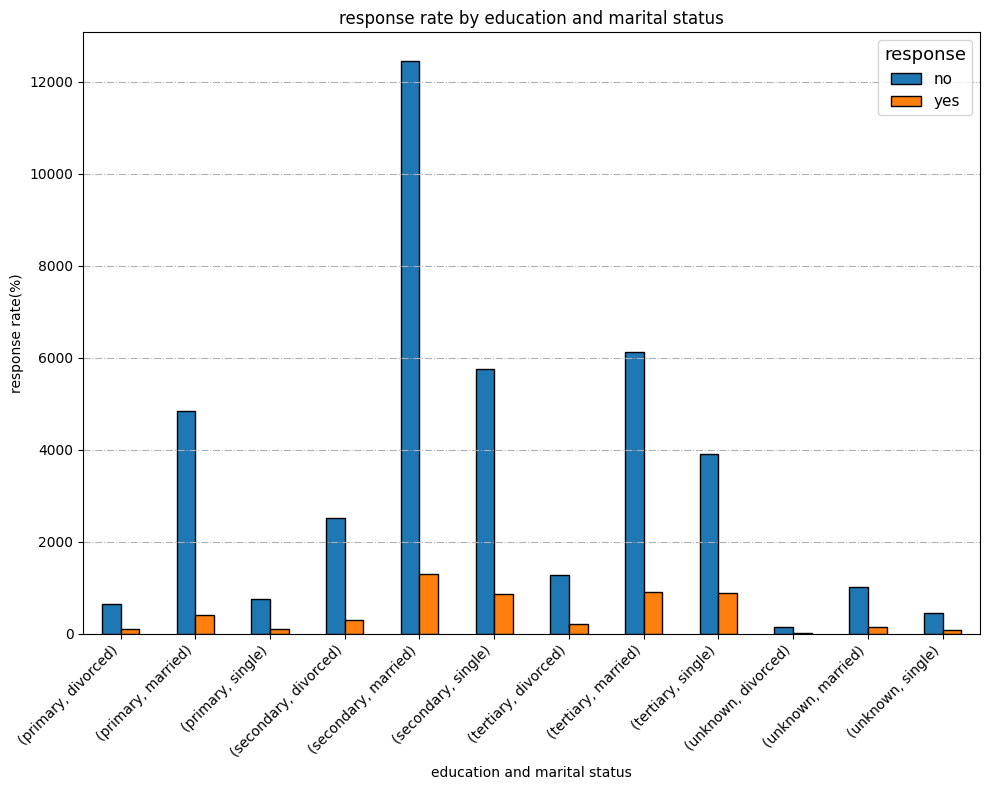

In [69]:
education_marital = pd.crosstab([df['education'], df['marital']], df['response'])

education_marital.plot(kind ='bar', figsize =(10,8), edgecolor = 'black')

plt.xlabel('education and marital status')
plt.ylabel('response rate(%)')
plt.title('response rate by education and marital status')

plt.xticks(rotation = 45, ha = 'right')
plt.legend(title = 'response', title_fontsize = '13', fontsize = '11')

plt.grid(axis = 'y', linestyle = '-.')
plt.tight_layout()
plt.show()

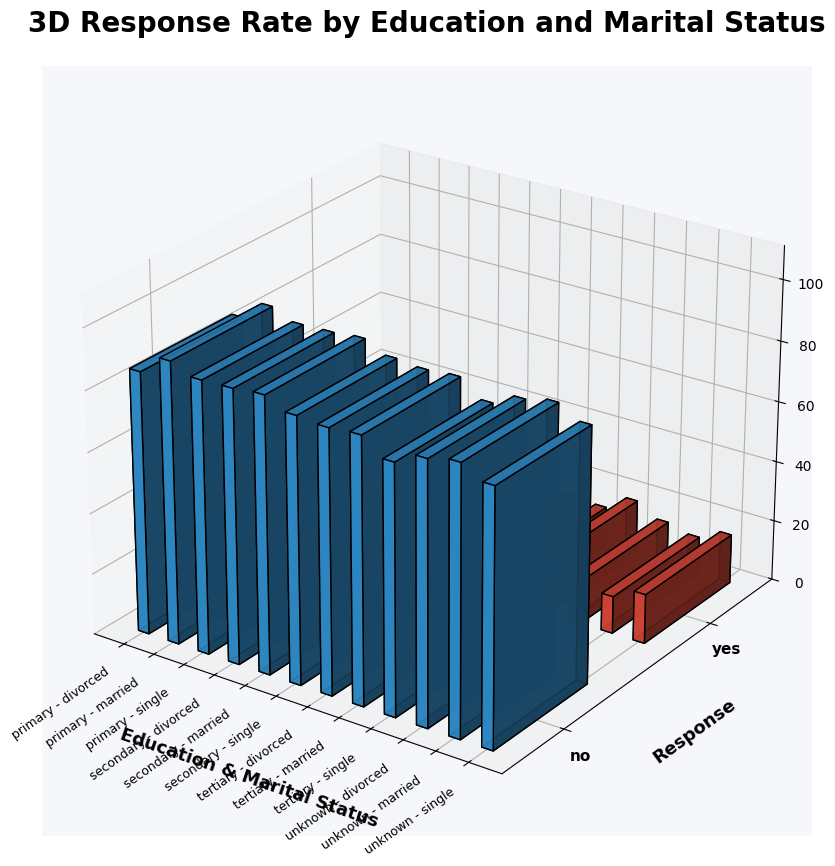

In [66]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Response rate (%)
education_marital = pd.crosstab(
    [df['education'], df['marital']],
    df['response'],
    normalize='index'
) * 100

# Create figure
fig = plt.figure(figsize=(16, 10))
ax = fig.add_subplot(111, projection='3d')

# Positions
x = np.arange(len(education_marital))
y_response1 = np.zeros(len(x))
y_response2 = np.ones(len(x)) * 0.9

# Bar size
dx = 0.35
dy = 0.55

# Response values
response1 = education_marital.iloc[:, 0].values
response2 = education_marital.iloc[:, 1].values

# First response
bars1 = ax.bar3d(
    x,
    y_response1,
    np.zeros(len(x)),
    dx,
    dy,
    response1,
    color='#3498DB',
    edgecolor='black',
    linewidth=1,
    alpha=0.9,
    shade=True
)

# Second response
bars2 = ax.bar3d(
    x,
    y_response2,
    np.zeros(len(x)),
    dx,
    dy,
    response2,
    color='#E74C3C',
    edgecolor='black',
    linewidth=1,
    alpha=0.9,
    shade=True
)

# X-axis labels
labels = [
    f'{education} - {marital}'
    for education, marital in education_marital.index
]

ax.set_xticks(x + dx / 2)

ax.set_xticklabels(
    labels,
    rotation=35,
    ha='right',
    fontsize=9
)

# Y-axis
ax.set_yticks([0.25, 1.15])

ax.set_yticklabels(
    education_marital.columns,
    fontsize=11,
    fontweight='bold'
)

# Axis labels
ax.set_xlabel(
    'Education & Marital Status',
    fontsize=13,
    fontweight='bold',
    labelpad=20
)

ax.set_ylabel(
    'Response',
    fontsize=13,
    fontweight='bold',
    labelpad=15
)

ax.set_zlabel(
    'Response Rate (%)',
    fontsize=13,
    fontweight='bold',
    labelpad=15
)

# Title
ax.set_title(
    '3D Response Rate by Education and Marital Status',
    fontsize=20,
    fontweight='bold',
    pad=25
)

# Set Z-axis range
ax.set_zlim(0, max(
    response1.max(),
    response2.max()
) * 1.2)

# 3D viewing angle
ax.view_init(
    elev=25,
    azim=-55
)

# Grid
ax.grid(
    True,
    linestyle='--',
    linewidth=0.6,
    alpha=0.5
)

# Background
ax.set_facecolor('#F5F7FA')

plt.tight_layout()
plt.show()